# Proyecto: Clasificación de animales con Animal-10

Este notebook documenta la exploración inicial del dataset **Animal-10**. La fase se limita deliberadamente al análisis exploratorio: no se divide el conjunto de datos, no se transforman imágenes y no se entrena ningún modelo.

# FASE 1 - EXPLORATORY DATA ANALYSIS

El objetivo es caracterizar la composición, el balance, las dimensiones, los formatos, el color y la calidad técnica de las imágenes. Todas las conclusiones se calculan a partir del contenido real de `data/` y se usan para proponer decisiones de preprocesamiento para la siguiente fase.

## 1. Carga de librerías

Se cargan librerías de propósito general, análisis tabular, visualización y lectura de imágenes. Se fija una semilla para que las muestras aleatorias sean reproducibles y una configuración gráfica uniforme de alta resolución, apropiada para un informe académico.

In [24]:
from pathlib import Path
from collections import Counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile, UnidentifiedImageError
from IPython.display import display, Markdown

SEED = 42
RNG = np.random.default_rng(SEED)
DATA_DIR = Path("data")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore", category=Image.DecompressionBombWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.autolayout": True,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

assert DATA_DIR.exists(), "No se encontró el directorio data/."
print(f"Entorno configurado. Semilla reproducible: {SEED}")

Entorno configurado. Semilla reproducible: 42


## 2. Exploración del dataset

Se recorre cada carpeta de clase y se valida cada archivo con Pillow. Para las imágenes legibles se registran dimensiones, formato, modo de color, peso y medias RGB. La lectura usada para color se reduce a 64×64 píxeles para mantener el análisis eficiente sin modificar los archivos originales. Los errores se conservan en un reporte separado.

Esta inspección establece la estructura real del dataset y evita que archivos no visuales o dañados contaminen análisis posteriores.

In [25]:
def discover_image_files(data_dir, extensions=IMAGE_EXTENSIONS):
    '''Devuelve carpetas de clase y archivos con extensiones de imagen conocidas.'''
    class_dirs = sorted([p for p in data_dir.iterdir() if p.is_dir()], key=lambda p: p.name)
    files = []
    for class_dir in class_dirs:
        files.extend((class_dir.name, p) for p in sorted(class_dir.rglob("*"))
                     if p.is_file() and p.suffix.lower() in extensions)
    return class_dirs, files


def inspect_dataset(data_dir):
    '''Valida imágenes y produce metadatos, errores y un histograma RGB agregado.'''
    class_dirs, candidates = discover_image_files(data_dir)
    records, problems = [], []
    rgb_hist = np.zeros((3, 256), dtype=np.int64)

    for class_name, path in candidates:
        try:
            file_bytes = path.stat().st_size
            if file_bytes == 0:
                problems.append({"clase": class_name, "archivo": str(path),
                                 "problema": "archivo vacío (0 bytes)"})
                continue

            with Image.open(path) as verify_img:
                verify_img.verify()

            with Image.open(path) as img:
                width, height = img.size
                if width <= 0 or height <= 0:
                    problems.append({"clase": class_name, "archivo": str(path),
                                     "problema": "dimensiones vacías"})
                    continue
                original_format = img.format or path.suffix.lstrip(".").upper()
                original_mode = img.mode
                rgb = img.convert("RGB")
                preview = np.asarray(rgb.resize((64, 64)), dtype=np.uint8)
                means = preview.reshape(-1, 3).mean(axis=0)
                for channel in range(3):
                    rgb_hist[channel] += np.bincount(preview[..., channel].ravel(), minlength=256)

            records.append({
                "clase": class_name,
                "archivo": str(path),
                "extension": path.suffix.lower(),
                "formato": original_format,
                "modo": original_mode,
                "bytes": file_bytes,
                "ancho": width,
                "alto": height,
                "pixeles": width * height,
                "aspect_ratio": width / height,
                "media_R": means[0],
                "media_G": means[1],
                "media_B": means[2],
            })
        except Exception as exc:
            problems.append({"clase": class_name, "archivo": str(path),
                             "problema": f"corrupta/no legible: {type(exc).__name__}: {exc}"})

    return class_dirs, candidates, pd.DataFrame(records), pd.DataFrame(problems), rgb_hist


class_dirs, candidate_files, images_df, corrupt_df, rgb_hist = inspect_dataset(DATA_DIR)
class_names = [p.name for p in class_dirs]
format_counts = images_df["formato"].value_counts().rename_axis("formato").to_frame("cantidad")
mode_counts = images_df["modo"].value_counts().rename_axis("modo").to_frame("cantidad")

print(f"Archivos candidatos: {len(candidate_files):,}")
print(f"Imágenes válidas: {len(images_df):,}")
print(f"Clases: {len(class_names)}")
print("Nombres:", ", ".join(class_names))
print(f"Imágenes corruptas o vacías: {len(corrupt_df):,}")
display(Markdown("**Formatos detectados**"), format_counts)
display(Markdown("**Modos de imagen detectados**"), mode_counts)

if len(images_df) == len(candidate_files):
    print("Interpretación automática: todos los archivos candidatos pudieron abrirse y decodificarse.")
else:
    print(f"Interpretación automática: {len(candidate_files)-len(images_df)} archivo(s) requieren revisión o exclusión.")

Archivos candidatos: 26,179
Imágenes válidas: 26,179
Clases: 10
Nombres: cane, cavallo, elefante, farfalla, gallina, gatto, mucca, pecora, ragno, scoiattolo
Imágenes corruptas o vacías: 0


**Formatos detectados**

,cantidad
formato,
JPEG,26128
PNG,51


**Modos de imagen detectados**

,cantidad
modo,
RGB,26128
RGBA,49
L,1
CMYK,1


Interpretación automática: todos los archivos candidatos pudieron abrirse y decodificarse.


## 3. Distribución de clases

El gráfico de barras permite comparar cantidades absolutas y el gráfico circular muestra la participación relativa. Se calcula además la razón entre la clase mayoritaria y la minoritaria y el coeficiente de variación. Estas medidas indican si en la siguiente fase será necesario conservar proporciones mediante estratificación y aplicar estrategias contra el sesgo de clase.

,cantidad,porcentaje
clase,,
cane,4863,18.58
cavallo,2623,10.02
elefante,1446,5.52
farfalla,2112,8.07
gallina,3098,11.83
gatto,1668,6.37
mucca,1866,7.13
pecora,1820,6.95
ragno,4821,18.42


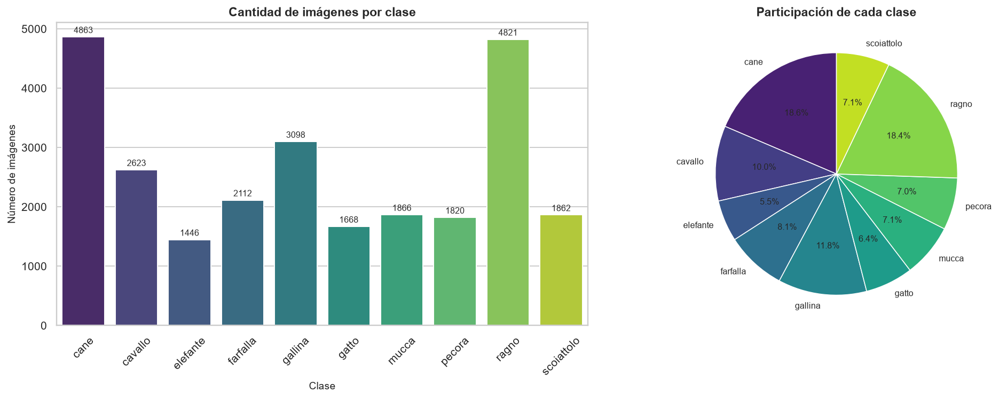

Interpretación automática: desbalance alto. La clase mayoritaria es 'cane' (4,863) y la minoritaria es 'elefante' (1,446); razón = 3.36:1, CV = 0.48.


In [26]:
class_counts = (images_df["clase"].value_counts()
                .reindex(class_names, fill_value=0)
                .rename("cantidad").to_frame())
class_counts["porcentaje"] = 100 * class_counts["cantidad"] / class_counts["cantidad"].sum()
class_counts.index.name = "clase"
display(class_counts)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = sns.color_palette("viridis", n_colors=len(class_counts))

sns.barplot(data=class_counts.reset_index(), x="clase", y="cantidad", hue="clase",
            palette=colors, legend=False, ax=axes[0])
axes[0].set_title("Cantidad de imágenes por clase")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Número de imágenes")
axes[0].tick_params(axis="x", rotation=45)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", fontsize=8, padding=2)

axes[1].pie(class_counts["cantidad"], labels=class_counts.index, autopct="%1.1f%%",
            startangle=90, colors=colors, textprops={"fontsize": 8},
            wedgeprops={"edgecolor": "white", "linewidth": 0.8})
axes[1].set_title("Participación de cada clase")
plt.show()

majority = class_counts["cantidad"].idxmax()
minority = class_counts["cantidad"].idxmin()
imbalance_ratio = class_counts["cantidad"].max() / class_counts["cantidad"].min()
cv_counts = class_counts["cantidad"].std() / class_counts["cantidad"].mean()
balance_level = "alto" if imbalance_ratio >= 2 else ("moderado" if imbalance_ratio >= 1.5 else "bajo")
print(f"Interpretación automática: desbalance {balance_level}. La clase mayoritaria es '{majority}' "
      f"({class_counts.loc[majority, 'cantidad']:,}) y la minoritaria es '{minority}' "
      f"({class_counts.loc[minority, 'cantidad']:,}); razón = {imbalance_ratio:.2f}:1, CV = {cv_counts:.2f}.")

## 4. Tamaño de imágenes

Se analizan anchos, altos, área total y relación de aspecto. Los histogramas evidencian resoluciones frecuentes, mientras el diagrama de dispersión muestra heterogeneidad y orientación. El resumen por clase incluye cantidad, promedio, desviación estándar, mínimo y máximo tanto para ancho como para alto.

La variabilidad observada determinará la resolución común y la política de redimensionamiento de la siguiente fase; todavía no se realiza ninguna transformación.

,cantidad,ancho_promedio,ancho_std,ancho_min,ancho_max,alto_promedio,alto_std,alto_min,alto_max,megapixeles_promedio
clase,,,,,,,,,,
cane,4863,283.57,33.94,109,300,241.09,47.26,101,300,0.07
cavallo,2623,287.95,30.98,60,300,233.47,41.56,57,300,0.07
elefante,1446,377.62,149.13,189,640,274.92,111.73,115,640,0.12
farfalla,2112,364.55,141.67,65,640,280.42,103.82,64,640,0.11
gallina,3098,288.30,28.23,82,300,239.36,44.10,95,300,0.07
gatto,1668,473.16,686.70,107,6720,364.57,511.37,75,6000,0.50
mucca,1866,294.18,21.02,120,300,212.75,35.74,86,300,0.06
pecora,1820,363.05,140.48,107,640,263.37,99.18,71,640,0.11
ragno,4821,311.14,89.26,88,640,247.83,71.71,80,640,0.08


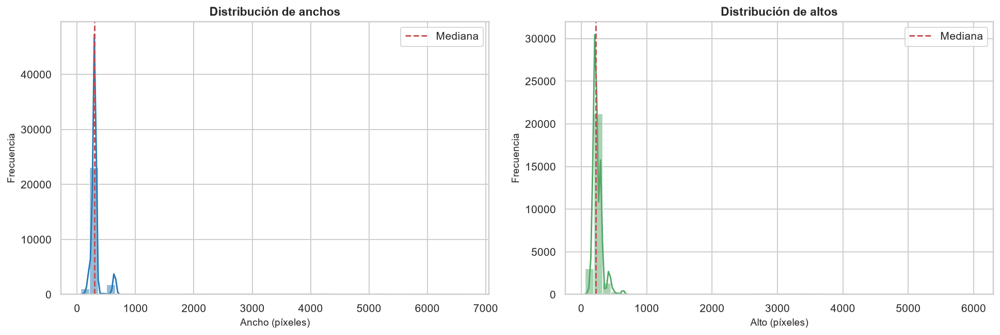

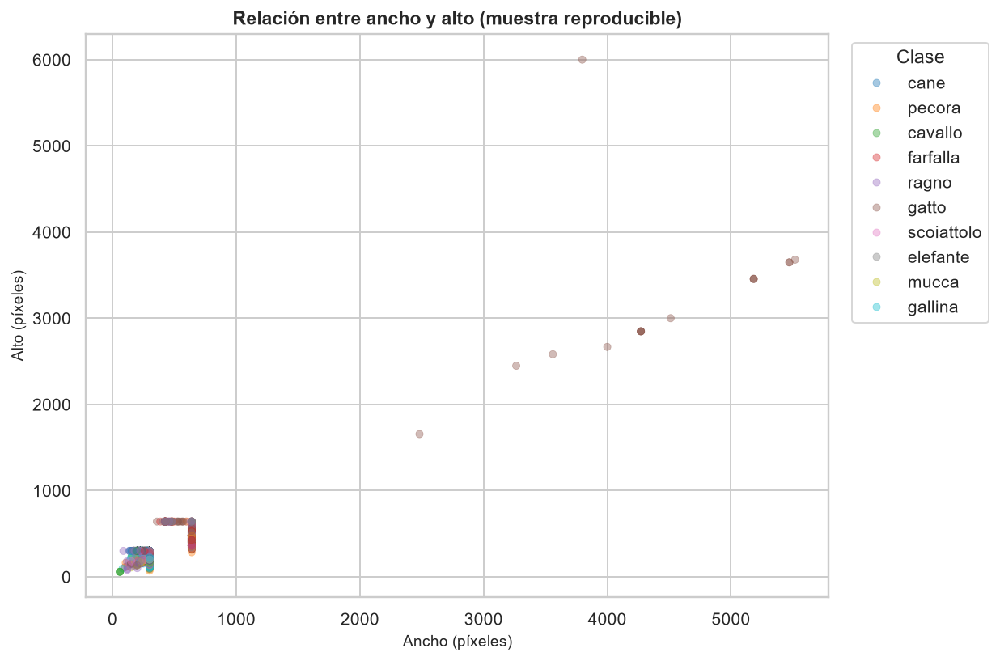

Interpretación automática: la mediana es 300×225 px. Los tamaños van de 60×57 hasta dimensiones máximas independientes de 6720 px de ancho y 6000 px de alto. La dispersión confirma que será necesario normalizar dimensiones antes de modelar.


In [27]:
def dimension_summary(df):
    summary = df.groupby("clase").agg(
        cantidad=("archivo", "size"),
        ancho_promedio=("ancho", "mean"), ancho_std=("ancho", "std"),
        ancho_min=("ancho", "min"), ancho_max=("ancho", "max"),
        alto_promedio=("alto", "mean"), alto_std=("alto", "std"),
        alto_min=("alto", "min"), alto_max=("alto", "max"),
        megapixeles_promedio=("pixeles", lambda s: s.mean() / 1e6),
    ).reindex(class_names)
    return summary


size_summary = dimension_summary(images_df)
display(size_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(images_df["ancho"], bins=45, color="#2878B5", kde=True, ax=axes[0])
axes[0].axvline(images_df["ancho"].median(), color="#C44E52", linestyle="--", label="Mediana")
axes[0].set(title="Distribución de anchos", xlabel="Ancho (píxeles)", ylabel="Frecuencia")
axes[0].legend()
sns.histplot(images_df["alto"], bins=45, color="#55A868", kde=True, ax=axes[1])
axes[1].axvline(images_df["alto"].median(), color="#C44E52", linestyle="--", label="Mediana")
axes[1].set(title="Distribución de altos", xlabel="Alto (píxeles)", ylabel="Frecuencia")
axes[1].legend()
plt.show()

plot_df = images_df.sample(min(10000, len(images_df)), random_state=SEED)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="ancho", y="alto", hue="clase", alpha=0.40,
                s=22, palette="tab10", edgecolor=None)
plt.title("Relación entre ancho y alto (muestra reproducible)")
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

print(f"Interpretación automática: la mediana es {images_df.ancho.median():.0f}×"
      f"{images_df.alto.median():.0f} px. Los tamaños van de "
      f"{images_df.ancho.min()}×{images_df.alto.min()} hasta dimensiones máximas independientes de "
      f"{images_df.ancho.max()} px de ancho y {images_df.alto.max()} px de alto. "
      "La dispersión confirma que será necesario normalizar dimensiones antes de modelar.")

## 5. Visualización de ejemplos

El mosaico 5×5 ofrece una revisión global reproducible de contenido, fondos, encuadres y variación intraclase. Después se genera una figura independiente por clase con ejemplos aleatorios, útil para detectar etiquetas visualmente ambiguas o patrones espurios.

Estas figuras son diagnósticas: no alteran las imágenes y no constituyen aumento de datos.

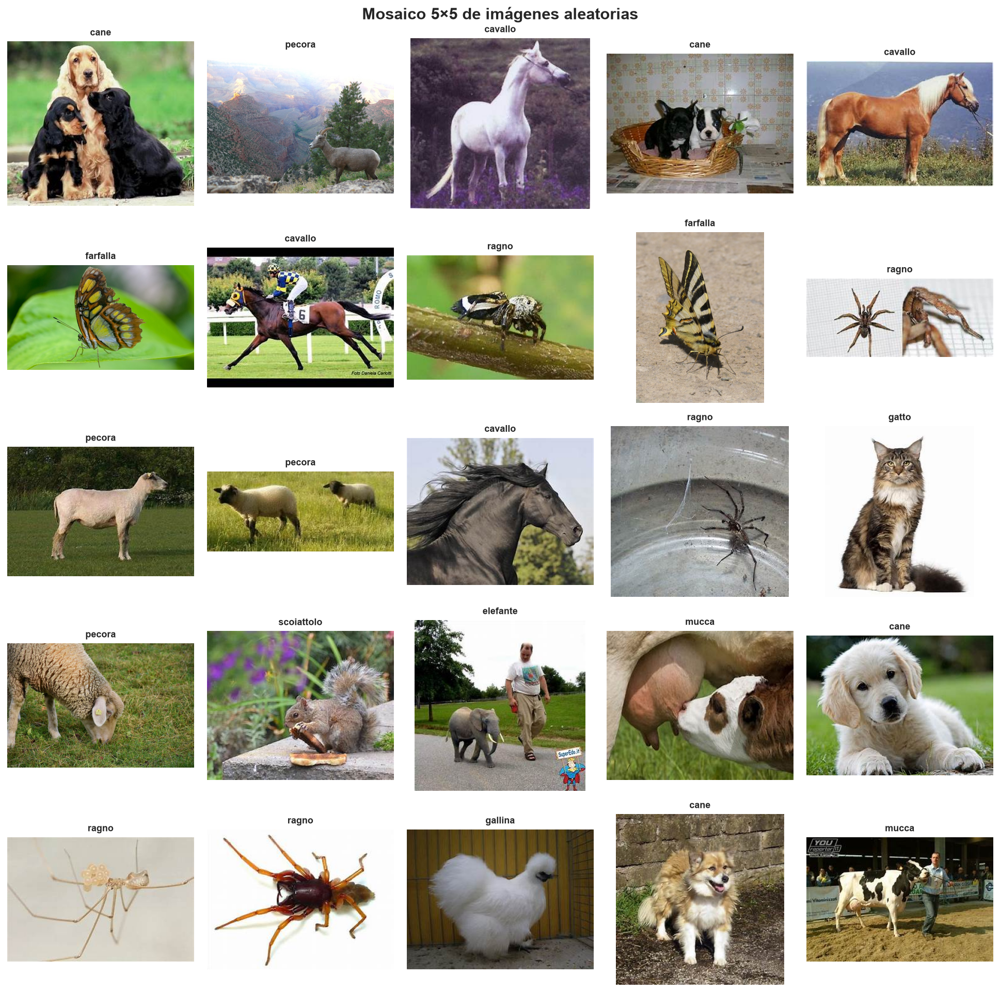

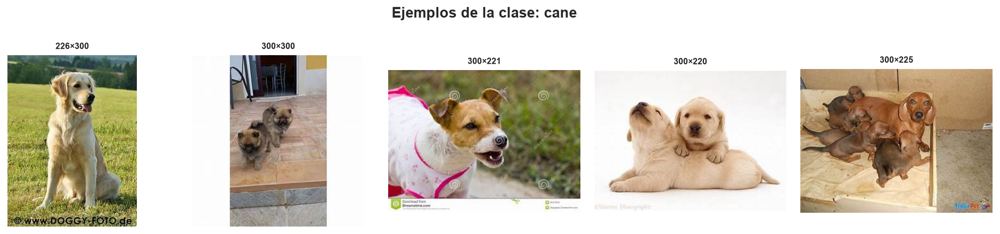

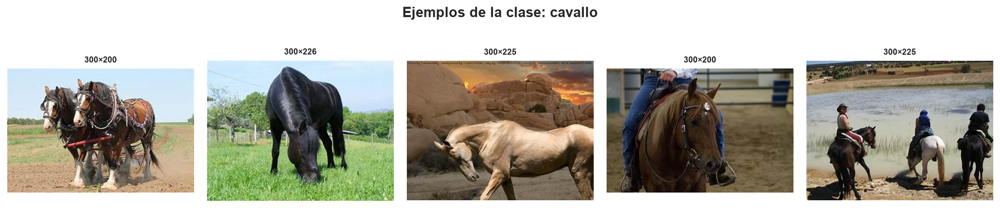

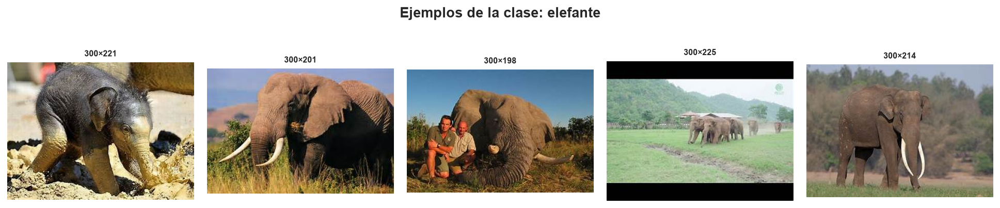

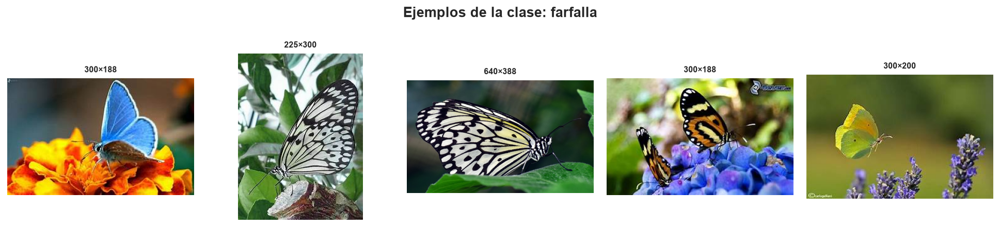

...

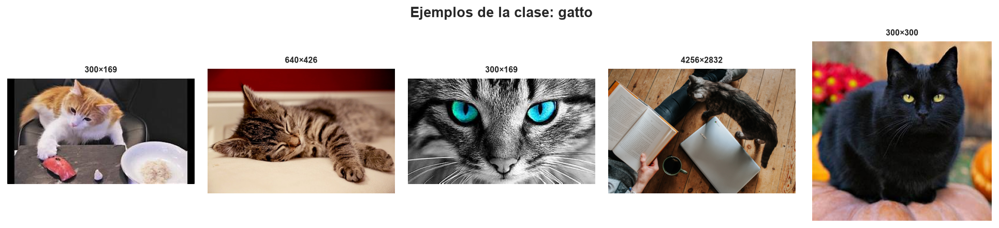

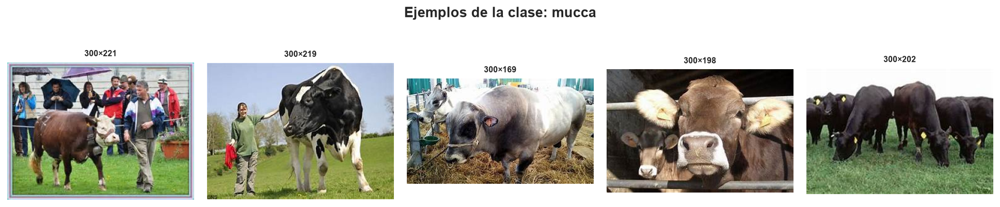

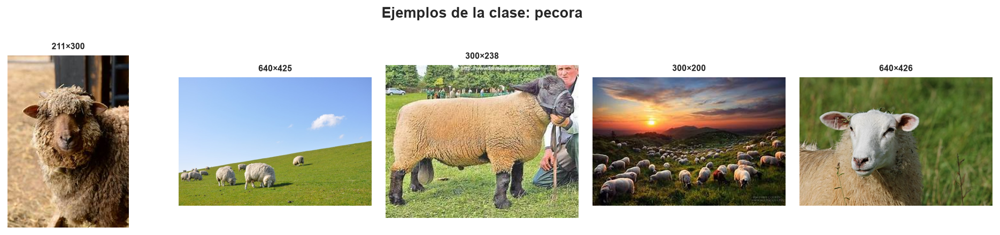

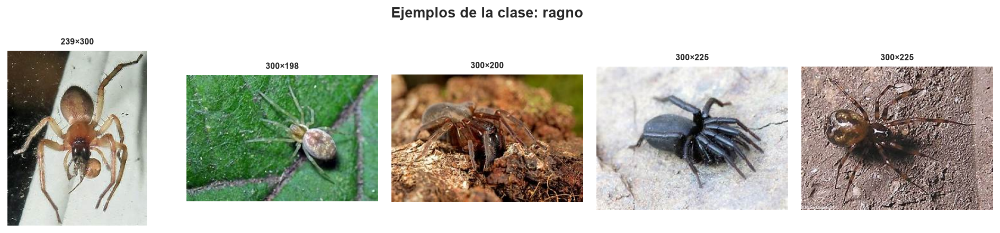

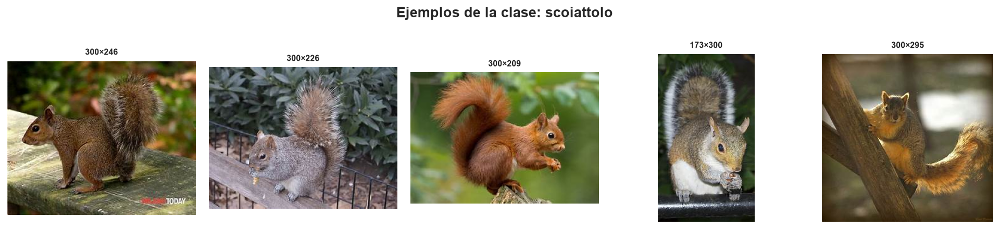

Interpretación automática: la inspección visual permite comprobar diversidad de fondos, escalas, poses y encuadres; la evaluación cuantitativa de calidad se presenta en la sección 7.


In [28]:
def show_random_mosaic(df, rows=5, cols=5, seed=SEED):
    sample = df.sample(min(rows * cols, len(df)), random_state=seed)
    fig, axes = plt.subplots(rows, cols, figsize=(14, 14))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, row) in zip(np.ravel(axes), sample.iterrows()):
        with Image.open(row["archivo"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(row["clase"], fontsize=9)
        ax.axis("off")
    fig.suptitle("Mosaico 5×5 de imágenes aleatorias", fontsize=16, fontweight="bold")
    plt.show()


def show_examples_by_class(df, class_order, n=5, seed=SEED):
    for offset, class_name in enumerate(class_order):
        subset = df[df["clase"] == class_name]
        sample = subset.sample(min(n, len(subset)), random_state=seed + offset)
        fig, axes = plt.subplots(1, n, figsize=(14, 3.2))
        for ax in np.ravel(axes):
            ax.axis("off")
        for ax, (_, row) in zip(np.ravel(axes), sample.iterrows()):
            with Image.open(row["archivo"]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{row['ancho']}×{row['alto']}", fontsize=8)
            ax.axis("off")
        fig.suptitle(f"Ejemplos de la clase: {class_name}", fontsize=14, fontweight="bold")
        plt.show()


show_random_mosaic(images_df)
show_examples_by_class(images_df, class_names)
print("Interpretación automática: la inspección visual permite comprobar diversidad de fondos, escalas, poses y encuadres; "
      "la evaluación cuantitativa de calidad se presenta en la sección 7.")

## 6. Estadísticas RGB

Los histogramas RGB agregan la frecuencia de intensidades de las miniaturas de todas las imágenes. La distribución de medias por imagen permite comparar dominantes de color entre clases. Finalmente, un heatmap resume conteo, geometría y color medio por clase después de estandarizar columnas, de modo que variables con escalas distintas sean comparables.

Si las clases presentan perfiles cromáticos muy diferentes, el color puede ser informativo, pero también puede reflejar fondos o contextos y convertirse en un atajo no deseado para el modelo.

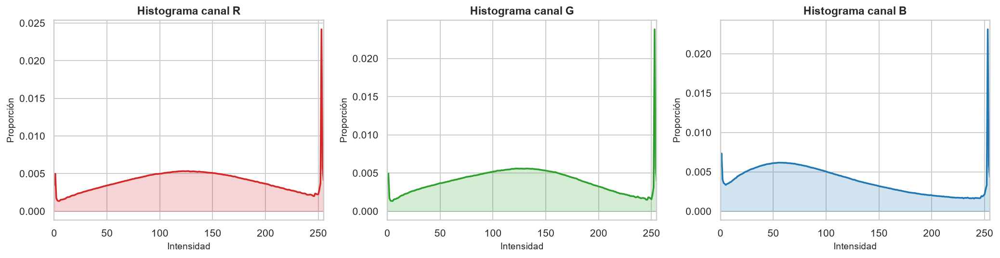

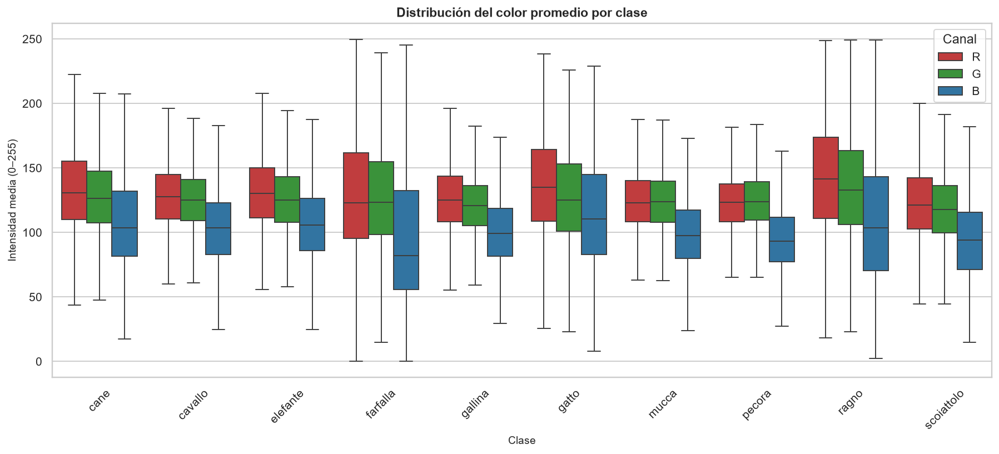

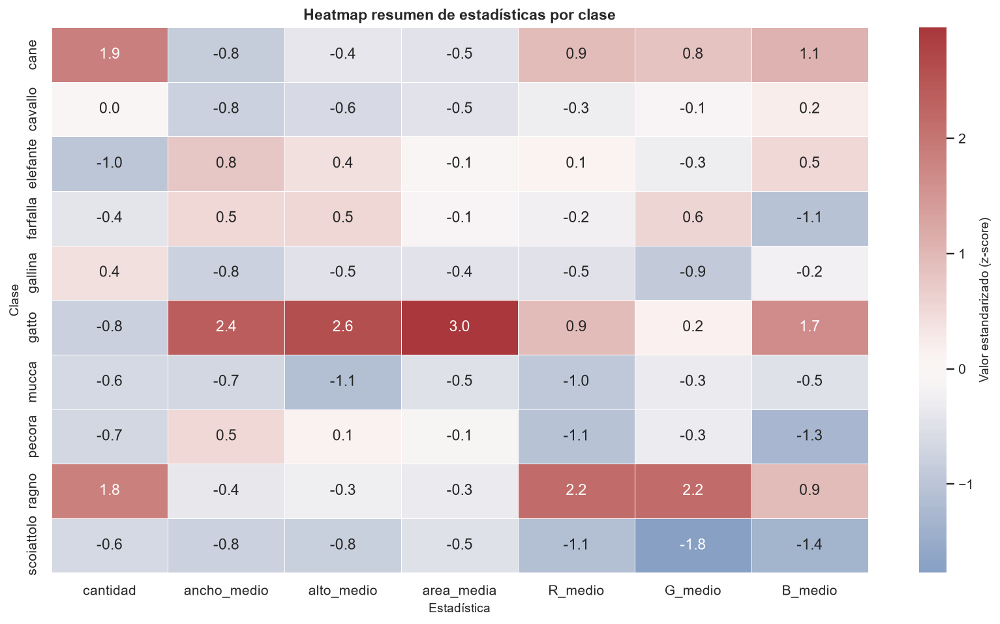

Interpretación automática: promedios globales R=132.0, G=127.6, B=105.2; el canal medio más alto es R. El heatmap revela qué clases se apartan del promedio en tamaño y color, por lo que conviene vigilar sesgos de fondo.


In [29]:
intensities = np.arange(256)
channel_spec = [("R", "#D62728"), ("G", "#2CA02C"), ("B", "#1F77B4")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, ((label, color), ax) in enumerate(zip(channel_spec, axes)):
    normalized = rgb_hist[idx] / rgb_hist[idx].sum()
    ax.plot(intensities, normalized, color=color, linewidth=1.8)
    ax.fill_between(intensities, normalized, color=color, alpha=0.20)
    ax.set(title=f"Histograma canal {label}", xlabel="Intensidad", ylabel="Proporción")
    ax.set_xlim(0, 255)
plt.show()

color_long = images_df.melt(id_vars=["clase"], value_vars=["media_R", "media_G", "media_B"],
                            var_name="canal", value_name="intensidad_media")
color_long["canal"] = color_long["canal"].str.replace("media_", "", regex=False)
plt.figure(figsize=(13, 6))
sns.boxplot(data=color_long, x="clase", y="intensidad_media", hue="canal",
            palette={"R": "#D62728", "G": "#2CA02C", "B": "#1F77B4"},
            showfliers=False)
plt.title("Distribución del color promedio por clase")
plt.xlabel("Clase")
plt.ylabel("Intensidad media (0–255)")
plt.xticks(rotation=45)
plt.legend(title="Canal")
plt.show()

heatmap_summary = images_df.groupby("clase").agg(
    cantidad=("archivo", "size"),
    ancho_medio=("ancho", "mean"),
    alto_medio=("alto", "mean"),
    area_media=("pixeles", "mean"),
    R_medio=("media_R", "mean"),
    G_medio=("media_G", "mean"),
    B_medio=("media_B", "mean"),
).reindex(class_names)
heatmap_z = (heatmap_summary - heatmap_summary.mean()) / heatmap_summary.std(ddof=0)
plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_z, cmap="vlag", center=0, annot=True, fmt=".1f",
            linewidths=0.5, cbar_kws={"label": "Valor estandarizado (z-score)"})
plt.title("Heatmap resumen de estadísticas por clase")
plt.xlabel("Estadística")
plt.ylabel("Clase")
plt.show()

global_rgb = images_df[["media_R", "media_G", "media_B"]].mean()
dominant = global_rgb.idxmax().replace("media_", "")
print(f"Interpretación automática: promedios globales R={global_rgb.media_R:.1f}, "
      f"G={global_rgb.media_G:.1f}, B={global_rgb.media_B:.1f}; el canal medio más alto es {dominant}. "
      "El heatmap revela qué clases se apartan del promedio en tamaño y color, por lo que conviene vigilar sesgos de fondo.")

## 7. Outliers y datos corruptos

Se consideran **extremadamente pequeñas** las imágenes cuyo lado menor es inferior a 64 px. Se consideran **extremadamente grandes** las que superan el umbral robusto de área `Q3 + 1.5×IQR`; también se informa el umbral calculado. Las imágenes vacías se detectan por peso cero o dimensiones no positivas, y las corruptas mediante verificación y decodificación completa.

Los umbrales son reglas transparentes de auditoría, no criterios automáticos de eliminación. Cada caso debe revisarse antes del preprocesamiento.

,problema,cantidad,criterio
0,Corruptas/no legibles o vacías,0,Pillow/0 bytes
1,Extremadamente pequeñas,5,lado menor < 64px
2,Extremadamente grandes,1970,"área > 95,250px"
3,Relación de aspecto extrema,21,ratio < 0.35 o > 2.85


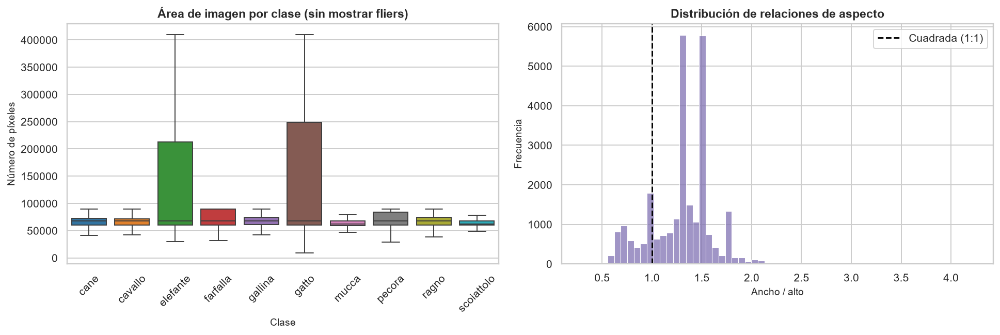

Interpretación automática: 0 corrupta(s)/vacía(s), 5 pequeña(s), 1970 grande(s) según IQR, 21 con aspecto extremo y 2 imagen(es) en modos distintos de RGB/RGBA. Los casos son candidatos a revisión, no a borrado automático.


In [30]:
def build_quality_report(df, corrupt, small_side=64):
    q1, q3 = df["pixeles"].quantile([0.25, 0.75])
    iqr = q3 - q1
    large_threshold = q3 + 1.5 * iqr
    small = df[df[["ancho", "alto"]].min(axis=1) < small_side].copy()
    large = df[df["pixeles"] > large_threshold].copy()
    extreme_aspect = df[(df["aspect_ratio"] < 0.35) | (df["aspect_ratio"] > 2.85)].copy()
    rows = [
        {"problema": "Corruptas/no legibles o vacías", "cantidad": len(corrupt), "criterio": "Pillow/0 bytes"},
        {"problema": "Extremadamente pequeñas", "cantidad": len(small), "criterio": f"lado menor < {small_side}px"},
        {"problema": "Extremadamente grandes", "cantidad": len(large), "criterio": f"área > {large_threshold:,.0f}px"},
        {"problema": "Relación de aspecto extrema", "cantidad": len(extreme_aspect), "criterio": "ratio < 0.35 o > 2.85"},
    ]
    return pd.DataFrame(rows), small, large, extreme_aspect, large_threshold


quality_report, small_df, large_df, aspect_df, large_threshold = build_quality_report(images_df, corrupt_df)
display(quality_report)
if not corrupt_df.empty:
    display(Markdown("**Detalle de archivos corruptos, vacíos o no legibles**"), corrupt_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=images_df, x="clase", y="pixeles", hue="clase", palette="tab10",
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("Área de imagen por clase (sin mostrar fliers)")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Número de píxeles")
axes[0].tick_params(axis="x", rotation=45)
sns.histplot(images_df["aspect_ratio"], bins=60, color="#8172B3", ax=axes[1])
axes[1].axvline(1, color="black", linestyle="--", label="Cuadrada (1:1)")
axes[1].set_title("Distribución de relaciones de aspecto")
axes[1].set_xlabel("Ancho / alto")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
plt.show()

non_rgb = int((~images_df["modo"].isin(["RGB", "RGBA"])).sum())
print(f"Interpretación automática: {len(corrupt_df)} corrupta(s)/vacía(s), {len(small_df)} pequeña(s), "
      f"{len(large_df)} grande(s) según IQR, {len(aspect_df)} con aspecto extremo y "
      f"{non_rgb} imagen(es) en modos distintos de RGB/RGBA. Los casos son candidatos a revisión, no a borrado automático.")

## 8. Hallazgos principales

Esta sección convierte los resultados anteriores en conclusiones reproducibles y actualiza `avance.md`. Las recomendaciones anticipan la Fase 2, pero no ejecutan divisiones, transformaciones ni modelos.

In [31]:
median_w, median_h = images_df["ancho"].median(), images_df["alto"].median()
target_resolution = 224
augmentation_needed = imbalance_ratio >= 1.5
balancing_needed = imbalance_ratio >= 1.5

findings = [
    f"El dataset contiene {len(images_df):,} imágenes válidas distribuidas en {len(class_names)} clases.",
    f"Existe desbalance {balance_level}: razón mayoritaria/minoritaria de {imbalance_ratio:.2f}:1.",
    f"La resolución mediana es {median_w:.0f}×{median_h:.0f} px y las dimensiones son heterogéneas.",
    f"Se detectaron {len(format_counts)} formatos de imagen: {', '.join(format_counts.index.astype(str))}.",
    f"La auditoría encontró {len(corrupt_df)} archivos corruptos/vacíos, {len(small_df)} imágenes muy pequeñas y {len(large_df)} muy grandes según IQR.",
    "Las distribuciones RGB cambian entre clases; el color puede aportar señal, pero también codificar fondos/contextos.",
]

display(Markdown("### Conclusiones automáticas\n" + "\n".join(f"- {x}" for x in findings)))

distribution_lines = ["| clase | cantidad | porcentaje |", "|---|---:|---:|"]
for class_name, row in class_counts.iterrows():
    distribution_lines.append(f"| {class_name} | {int(row['cantidad'])} | {row['porcentaje']:.2f}% |")
distribution_md = "\n".join(distribution_lines)
risks = [
    f"Desbalance de clases ({imbalance_ratio:.2f}:1) entre {majority} y {minority}.",
    f"{len(corrupt_df)} archivos corruptos, vacíos o no legibles.",
    f"{len(small_df)} imágenes con lado menor a 64 px y {len(large_df)} outliers grandes por área.",
    f"Heterogeneidad de resolución, relación de aspecto y modos de color ({non_rgb} no RGB/RGBA).",
]

avance_text = f'''# Fase 1 - EDA

## Resumen del Dataset

- **Número total de archivos candidatos:** {len(candidate_files):,}
- **Número total de imágenes válidas:** {len(images_df):,}
- **Número de clases:** {len(class_names)}
- **Nombres de clases:** {', '.join(class_names)}
- **Formatos detectados:** {', '.join(format_counts.index.astype(str))}

## Distribución

{distribution_md}

La razón entre la clase mayoritaria y la minoritaria es **{imbalance_ratio:.2f}:1**, lo que representa un desbalance **{balance_level}**.

## Hallazgos

{chr(10).join(f'- {x}' for x in findings)}

## Riesgos detectados

{chr(10).join(f'- {x}' for x in risks)}

## Recomendaciones para Fase 2

- **Resolución objetivo sugerida:** {target_resolution}×{target_resolution} px, preservando relación de aspecto mediante resize + padding o crop controlado. Confirmar según el modelo que se seleccione posteriormente.
- **División sugerida:** train/validation/test estratificada (por ejemplo 70/15/15), con semilla fija. Antes de dividir, investigar duplicados para evitar fuga de información. Esta división aún no se ha ejecutado.
- **Data augmentation:** {'sí, recomendada' if augmentation_needed else 'opcional'}, aplicada solo al conjunto de entrenamiento; priorizar transformaciones geométricas y fotométricas moderadas.
- **Balanceo:** {'sí, considerar pesos de clase, muestreo o augmentation focalizada' if balancing_needed else 'no parece imprescindible'}, y evaluar métricas macro además de accuracy.
- Convertir de forma consistente a RGB y normalizar valores de píxel en la fase de preprocesamiento.
- Revisar manualmente los outliers reportados antes de excluir cualquier archivo.

> Archivo generado automáticamente por `animal10_project.ipynb` a partir del contenido actual de `data/`.
'''
Path("avance.md").write_text(avance_text, encoding="utf-8")
print("avance.md actualizado correctamente.")

### Conclusiones automáticas
- El dataset contiene 26,179 imágenes válidas distribuidas en 10 clases.
- Existe desbalance alto: razón mayoritaria/minoritaria de 3.36:1.
- La resolución mediana es 300×225 px y las dimensiones son heterogéneas.
- Se detectaron 2 formatos de imagen: JPEG, PNG.
- La auditoría encontró 0 archivos corruptos/vacíos, 5 imágenes muy pequeñas y 1970 muy grandes según IQR.
- Las distribuciones RGB cambian entre clases; el color puede aportar señal, pero también codificar fondos/contextos.

avance.md actualizado correctamente.


# DECISIÓN PARA CONTINUAR

La decisión se genera a partir de los indicadores calculados. Define el punto de partida para el preprocesamiento, sin implementarlo todavía.

In [32]:
decision = f'''
### 1. ¿Qué aprendimos del dataset?

Animal-10 contiene **{len(images_df):,} imágenes válidas** de **{len(class_names)} clases**. La distribución presenta un desbalance **{balance_level}** ({imbalance_ratio:.2f}:1), las dimensiones y relaciones de aspecto son heterogéneas, y se detectaron {len(corrupt_df)} archivos corruptos/vacíos. La variación visual y cromática es relevante y podría incluir señal de contexto.

### 2. ¿Qué debemos hacer en Fase 2?

Definir un pipeline reproducible que convierta a RGB, trate los casos de calidad tras revisión, redimensione de manera consistente y prepare una división estratificada sin fuga de información. La augmentation debe aplicarse únicamente a entrenamiento. Deben conservarse métricas sensibles al desbalance.

### 3. Parámetros propuestos para el preprocesamiento

- Resolución inicial: **{target_resolution}×{target_resolution} px**.
- Canales: **RGB (3 canales)**.
- Redimensionamiento: preservar aspecto con **padding o crop controlado**.
- Escala de píxel: **[0, 1]** o la normalización requerida por el modelo futuro.
- Semilla: **{SEED}**.
- División futura sugerida: **70/15/15 estratificada**, después de revisar duplicados.
- Augmentation futura: flips horizontales, rotaciones/traslaciones leves y ajustes moderados de color, solo en train.
- Balance: considerar **pesos de clase** o muestreo controlado y reportar métricas macro.

**Estado:** Fase 1 completada. No se ha dividido el dataset ni se ha implementado ningún modelo.
'''
display(Markdown(decision))


### 1. ¿Qué aprendimos del dataset?

Animal-10 contiene **26,179 imágenes válidas** de **10 clases**. La distribución presenta un desbalance **alto** (3.36:1), las dimensiones y relaciones de aspecto son heterogéneas, y se detectaron 0 archivos corruptos/vacíos. La variación visual y cromática es relevante y podría incluir señal de contexto.

### 2. ¿Qué debemos hacer en Fase 2?

Definir un pipeline reproducible que convierta a RGB, trate los casos de calidad tras revisión, redimensione de manera consistente y prepare una división estratificada sin fuga de información. La augmentation debe aplicarse únicamente a entrenamiento. Deben conservarse métricas sensibles al desbalance.

### 3. Parámetros propuestos para el preprocesamiento

- Resolución inicial: **224×224 px**.
- Canales: **RGB (3 canales)**.
- Redimensionamiento: preservar aspecto con **padding o crop controlado**.
- Escala de píxel: **[0, 1]** o la normalización requerida por el modelo futuro.
- Semilla: **42**.
- División futura sugerida: **70/15/15 estratificada**, después de revisar duplicados.
- Augmentation futura: flips horizontales, rotaciones/traslaciones leves y ajustes moderados de color, solo en train.
- Balance: considerar **pesos de clase** o muestreo controlado y reportar métricas macro.

**Estado:** Fase 1 completada. No se ha dividido el dataset ni se ha implementado ningún modelo.


# FASE 2 - PREPROCESSING AND DATA SPLIT

Esta fase construye un inventario reproducible, audita duplicados y calidad, crea una división estratificada y define el pipeline de lectura. **No se entrena ningún modelo**. Para prevenir fuga de información, las imágenes relacionadas por duplicación exacta o perceptual se mantienen en el mismo split.

## 1. Carga de metadatos

Se reutilizan los metadatos validados en la Fase 1 y se añade la fecha de modificación de cada archivo. El inventario se guarda como respaldo reproducible. Las rutas se normalizan de forma relativa al proyecto para que los manifiestos sean portables.

In [33]:
import hashlib
import itertools
from collections import defaultdict
from scipy.fft import dctn
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from PIL import ImageOps, ImageEnhance

TARGET_SIZE = (224, 224)
SPLIT_SEED = 42

required_columns = {"archivo", "clase", "ancho", "alto", "pixeles", "modo"}
if "images_df" not in globals() or not required_columns.issubset(images_df.columns):
    raise RuntimeError("Ejecute primero la Fase 1 para reconstruir los metadatos validados.")

metadata_df = images_df.copy()
metadata_df["filepath"] = metadata_df["archivo"].map(lambda p: Path(p).as_posix())
metadata_df["mtime_ns"] = metadata_df["archivo"].map(lambda p: Path(p).stat().st_mtime_ns)
metadata_df.to_csv("phase2_metadata.csv", index=False, encoding="utf-8")

print(f"Metadatos cargados: {len(metadata_df):,} imágenes, {metadata_df['clase'].nunique()} clases.")
print(f"Resolución objetivo: {TARGET_SIZE[0]}×{TARGET_SIZE[1]} px; semilla: {SPLIT_SEED}.")
assert len(metadata_df) == 26179 and metadata_df["clase"].nunique() == 10

Metadatos cargados: 26,179 imágenes, 10 clases.
Resolución objetivo: 224×224 px; semilla: 42.


## 2. Búsqueda de posibles duplicados

Se calculan tres huellas complementarias:

- **MD5:** detecta archivos exactamente iguales byte a byte.
- **Average hash (aHash):** resume la luminosidad global en 64 bits.
- **Perceptual hash (pHash):** resume frecuencias visuales mediante DCT y tolera cambios leves.

Un par no exacto se marca como duplicado potencial cuando tiene distancia de Hamming ≤5 simultáneamente en pHash y aHash. La búsqueda pHash usa un árbol BK para evitar una comparación cuadrática completa. Los resultados se guardan para revisión y **no se elimina ningún archivo**.

In [34]:
def md5_file(path, chunk_size=1024 * 1024):
    digest = hashlib.md5()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def binary_hash_to_hex(bits):
    value = 0
    for bit in bits.ravel():
        value = (value << 1) | int(bit)
    return f"{value:016x}"


def image_hashes(path):
    with Image.open(path) as img:
        gray8 = np.asarray(img.convert("L").resize((8, 8), Image.Resampling.LANCZOS), dtype=np.float32)
        ahash = binary_hash_to_hex(gray8 >= gray8.mean())
        gray32 = np.asarray(img.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
        low_freq = dctn(gray32, type=2, norm="ortho")[:8, :8]
        threshold = np.median(low_freq.ravel()[1:])
        phash = binary_hash_to_hex(low_freq >= threshold)
    return ahash, phash


def hamming_hex(left, right):
    return (int(left, 16) ^ int(right, 16)).bit_count()


hash_cache_path = Path("image_hashes.csv")
cache_ok = False
if hash_cache_path.exists():
    cached = pd.read_csv(hash_cache_path, dtype={"md5": str, "ahash": str, "phash": str})
    expected = metadata_df[["filepath", "bytes", "mtime_ns"]].copy()
    if len(cached) == len(expected) and {"filepath", "bytes", "mtime_ns", "md5", "ahash", "phash"}.issubset(cached.columns):
        cache_ok = cached[["filepath", "bytes", "mtime_ns"]].sort_values("filepath").reset_index(drop=True).equals(
            expected.sort_values("filepath").reset_index(drop=True)
        )

if cache_ok:
    hashes_df = cached
    print("Hashes cargados desde caché validada.")
else:
    hash_rows = []
    for number, row in enumerate(metadata_df.itertuples(index=False), start=1):
        ahash, phash = image_hashes(row.archivo)
        hash_rows.append({"filepath": row.filepath, "bytes": row.bytes, "mtime_ns": row.mtime_ns,
                          "md5": md5_file(row.archivo), "ahash": ahash, "phash": phash})
        if number % 5000 == 0:
            print(f"Hashes calculados: {number:,}/{len(metadata_df):,}")
    hashes_df = pd.DataFrame(hash_rows)
    hashes_df.to_csv(hash_cache_path, index=False, encoding="utf-8")


class BKNode:
    def __init__(self, value, index):
        self.value, self.indices, self.children = value, [index], {}


class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value, index):
        if self.root is None:
            self.root = BKNode(value, index)
            return
        node = self.root
        while True:
            distance = (value ^ node.value).bit_count()
            if distance == 0:
                node.indices.append(index)
                return
            if distance not in node.children:
                node.children[distance] = BKNode(value, index)
                return
            node = node.children[distance]

    def query(self, value, radius):
        if self.root is None:
            return []
        found, stack = [], [self.root]
        while stack:
            node = stack.pop()
            distance = (value ^ node.value).bit_count()
            if distance <= radius:
                found.extend((idx, distance) for idx in node.indices)
            lower, upper = distance - radius, distance + radius
            stack.extend(child for edge, child in node.children.items() if lower <= edge <= upper)
        return found


hash_info = metadata_df[["filepath", "clase"]].merge(
    hashes_df[["filepath", "md5", "ahash", "phash"]], on="filepath", how="left", validate="one_to_one"
)

duplicate_rows = []
exact_edges = []
for md5_value, group in hash_info.groupby("md5"):
    if len(group) > 1:
        indices = group.index.tolist()
        for left, right in itertools.combinations(indices, 2):
            exact_edges.append((left, right))
            duplicate_rows.append({
                "tipo": "exacto", "archivo_1": hash_info.at[left, "filepath"],
                "clase_1": hash_info.at[left, "clase"], "archivo_2": hash_info.at[right, "filepath"],
                "clase_2": hash_info.at[right, "clase"], "md5": md5_value,
                "distancia_phash": 0, "distancia_ahash": 0,
            })

tree = BKTree()
potential_edges = []
for idx, row in hash_info.iterrows():
    pvalue = int(row["phash"], 16)
    for other_idx, pdistance in tree.query(pvalue, radius=5):
        if row["md5"] == hash_info.at[other_idx, "md5"]:
            continue
        adistance = hamming_hex(row["ahash"], hash_info.at[other_idx, "ahash"])
        if adistance <= 5:
            potential_edges.append((other_idx, idx))
            duplicate_rows.append({
                "tipo": "potencial", "archivo_1": hash_info.at[other_idx, "filepath"],
                "clase_1": hash_info.at[other_idx, "clase"], "archivo_2": row["filepath"],
                "clase_2": row["clase"], "md5": "", "distancia_phash": pdistance,
                "distancia_ahash": adistance,
            })
    tree.add(pvalue, idx)

duplicate_review_df = pd.DataFrame(duplicate_rows, columns=[
    "tipo", "archivo_1", "clase_1", "archivo_2", "clase_2", "md5", "distancia_phash", "distancia_ahash"
])
duplicate_review_df.to_csv("duplicate_review.csv", index=False, encoding="utf-8")
exact_count = int((duplicate_review_df["tipo"] == "exacto").sum()) if len(duplicate_review_df) else 0
potential_count = int((duplicate_review_df["tipo"] == "potencial").sum()) if len(duplicate_review_df) else 0
cross_label_count = int((duplicate_review_df["clase_1"] != duplicate_review_df["clase_2"]).sum()) if len(duplicate_review_df) else 0
print(f"Pares exactos: {exact_count:,}; pares potenciales: {potential_count:,}; pares entre etiquetas distintas: {cross_label_count:,}.")
display(duplicate_review_df.head(20))
print("Decisión: conservar todos los archivos y guardar los pares para revisión manual; sus grupos no se separarán entre splits.")

Hashes cargados desde caché validada.
Pares exactos: 0; pares potenciales: 1,870; pares entre etiquetas distintas: 1.


,tipo,archivo_1,clase_1,archivo_2,clase_2,md5,distancia_phash,distancia_ahash
0,potencial,data/cane/OIP-0GhaPMWsyP-8rHQIiZwBOQHaJn.jpeg,cane,data/cane/OIP-2mo0pbriM0scgiEx6PJobgHaJn.jpeg,cane,,0,0
1,potencial,data/cane/OIP-49EzwfQF4PfsCfNjoR4WMAEsDZ.jpeg,cane,data/cane/OIP-49EzwfQF4PfsCfNjoR4WMAHaFW.jpeg,cane,,0,1
2,potencial,data/cane/OIP-36dvFVWrE_vhH3RPTjeO-gHaFj.jpeg,cane,data/cane/OIP-4dLYEI-L1JUJqO-ssPsrEAHaFj.jpeg,cane,,0,0
3,potencial,data/cane/OIP-5JhbrzBOwcu_LtDJcwnCngHaHa.jpeg,cane,data/cane/OIP-9I7XZqZMqY-Wou7zVUZ4QwHaHa.jpeg,cane,,0,0
4,potencial,data/cane/OIP-9o0fIVpLEISNKUAwpiEpGgHaFv.jpeg,cane,data/cane/OIP-_5GCQGVN9m7ed1UX_dUtTQHaFv.jpeg,cane,,0,0
5,potencial,data/cane/OIP-6ID1W9vWSfRIZem6NV_HHQHaE7.jpeg,cane,data/cane/OIP-_kph8rTC17LAZ6VFygxPbwHaE7.jpeg,cane,,2,0
6,potencial,data/cane/OIP-atuQV_J4-dv6v7YAVIoK1AHaFj.jpeg,cane,data/cane/OIP-aZO1bNmDPozukTqg4ToyewHaFj.jpeg,cane,,0,1
7,potencial,data/cane/OIP--XK9fGfui8Yd_sI6-rKx-AHaFj.jpeg,cane,data/cane/OIP-B5yaVsjCrx6JpY_j8i5fzgHaFj.jpeg,cane,,2,1
8,potencial,data/cane/OIP-7B3hQe8PHL8y0cUpmEB4OQHaFj.jpeg,cane,data/cane/OIP-BAhnDEB-1Y4-FbXETUE15wHaFj.jpeg,cane,,0,0
9,potencial,data/cane/OIP-_g_M1TKsvau0Um-NVpZjCgHaE7.jpeg,cane,data/cane/OIP-BFV29PuWiErLzyk5-OnsZwHaE7.jpeg,cane,,0,0


Decisión: conservar todos los archivos y guardar los pares para revisión manual; sus grupos no se separarán entre splits.


## 3. Tratamiento de imágenes problemáticas

Se reproducen los criterios de la Fase 1: lado menor <64 px para imágenes pequeñas y `Q3 + 1.5×IQR` del área para imágenes extremadamente grandes. Se genera la tabla solicitada con ruta, clase, dimensiones y área.

**Decisión:** no eliminar automáticamente. Las imágenes grandes pueden reducirse sin pérdida problemática; las pequeñas se conservan marcadas, ya que ampliarlas puede introducir desenfoque. El pipeline realizará conversión RGB y padding. La revisión manual queda respaldada en CSV.

In [35]:
q1_area, q3_area = metadata_df["pixeles"].quantile([0.25, 0.75])
large_area_threshold = q3_area + 1.5 * (q3_area - q1_area)
problem_df = metadata_df.loc[
    (metadata_df[["ancho", "alto"]].min(axis=1) < 64) | (metadata_df["pixeles"] > large_area_threshold),
    ["filepath", "clase", "ancho", "alto", "pixeles"]
].copy()
problem_df = problem_df.rename(columns={"pixeles": "area"})
problem_df["problema"] = np.where(
    problem_df[["ancho", "alto"]].min(axis=1) < 64,
    "extremadamente pequeña", "extremadamente grande (IQR)"
)
problem_df.to_csv("problem_images_review.csv", index=False, encoding="utf-8")

small_count = int((problem_df["problema"] == "extremadamente pequeña").sum())
large_count = int((problem_df["problema"] == "extremadamente grande (IQR)").sum())
print(f"Pequeñas: {small_count}; grandes: {large_count}; umbral de área grande: {large_area_threshold:,.0f} px.")
display(problem_df.head(20))

Pequeñas: 5; grandes: 1970; umbral de área grande: 95,250 px.


,filepath,clase,ancho,alto,area,problema
5106,data/cavallo/OIP-4UmK-NKWl1fwEK9GfBSGKAAAAA.jpeg,cavallo,60,57,3420,extremadamente pequeña
5487,data/cavallo/OIP-bT32YLeLizQNLnu4lcVGAAAAAA.jpeg,cavallo,60,57,3420,extremadamente pequeña
6148,data/cavallo/OIP-jqjnI-BWj-9BkPeqZetiggAAAA.jpeg,cavallo,60,57,3420,extremadamente pequeña
6189,data/cavallo/OIP-K8QgBSuaAkfMGBB_1C84uQAAAA.jpeg,cavallo,60,57,3420,extremadamente pequeña
7473,data/cavallo/OIP-zVErTw8mSPohwjPxvw6ehgAAAA.jpeg,cavallo,60,57,3420,extremadamente pequeña
7486,data/elefante/e032b10b2df21c22d2524518b7444f92...,elefante,640,426,272640,extremadamente grande (IQR)
7487,data/elefante/e130b80b2ef11c22d2524518b7444f92...,elefante,640,424,271360,extremadamente grande (IQR)
7488,data/elefante/e131b0072ee90021d85a5854ee454296...,elefante,640,463,296320,extremadamente grande (IQR)
7489,data/elefante/e132b10a2bf51c22d2524518b7444f92...,elefante,640,426,272640,extremadamente grande (IQR)
7490,data/elefante/e133b10d2bf21c22d2524518b7444f92...,elefante,640,426,272640,extremadamente grande (IQR)


## 4. Construcción del dataset maestro

El dataset maestro integra etiquetas, dimensiones, hashes, indicadores de calidad y un `duplicate_group`. Los grupos se construyen como componentes conectados: si A es similar a B y B a C, los tres permanecen juntos. Esto protege contra leakage incluso en cadenas de duplicados.

In [36]:
class UnionFind:
    def __init__(self, size):
        self.parent = list(range(size))
        self.rank = [0] * size

    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item

    def union(self, left, right):
        left_root, right_root = self.find(left), self.find(right)
        if left_root == right_root:
            return
        if self.rank[left_root] < self.rank[right_root]:
            left_root, right_root = right_root, left_root
        self.parent[right_root] = left_root
        if self.rank[left_root] == self.rank[right_root]:
            self.rank[left_root] += 1


union_find = UnionFind(len(hash_info))
for left, right in exact_edges + potential_edges:
    union_find.union(left, right)
root_to_group = {root: f"dup_{number:05d}" for number, root in enumerate(sorted({union_find.find(i) for i in range(len(hash_info))}))}
hash_info["duplicate_group"] = [root_to_group[union_find.find(i)] for i in range(len(hash_info))]

class_order = sorted(metadata_df["clase"].unique())
class_to_id = {name: idx for idx, name in enumerate(class_order)}
master_df = metadata_df.merge(
    hash_info[["filepath", "md5", "ahash", "phash", "duplicate_group"]],
    on="filepath", how="left", validate="one_to_one"
)
master_df["class_name"] = master_df["clase"]
master_df["class_id"] = master_df["class_name"].map(class_to_id).astype(int)
master_df["is_small"] = master_df[["ancho", "alto"]].min(axis=1) < 64
master_df["is_large_iqr"] = master_df["pixeles"] > large_area_threshold
master_df = master_df.rename(columns={"ancho": "width", "alto": "height", "pixeles": "area"})
master_columns = ["filepath", "class_name", "class_id", "width", "height", "area", "modo",
                  "md5", "ahash", "phash", "duplicate_group", "is_small", "is_large_iqr"]
master_df = master_df[master_columns].sort_values(["class_id", "filepath"]).reset_index(drop=True)
assert master_df["filepath"].is_unique and not master_df.isna().any().any()
master_df.to_csv("master_dataset.csv", index=False, encoding="utf-8")

group_sizes = master_df.groupby("duplicate_group").size()
print(f"Dataset maestro: {len(master_df):,} filas; grupos: {len(group_sizes):,}; grupos con más de una imagen: {(group_sizes > 1).sum():,}.")
display(master_df.head())

Dataset maestro: 26,179 filas; grupos: 24,763; grupos con más de una imagen: 1,150.


,filepath,class_name,class_id,width,height,area,modo,md5,ahash,phash,duplicate_group,is_small,is_large_iqr
0,data/cane/OIF-e2bexWrojgtQnAPPcUfOWQ.jpeg,cane,0,300,225,67500,RGB,fda3a63b57bb6bdf0b1af8ec110310be,dfc78f8f0f070303,a6d36c82bbfc9382,dup_00000,False,False
1,data/cane/OIP---A27bIBcUgX1qkbpZOPswHaFS.jpeg,cane,0,300,214,64200,RGB,1d5e33460ed7a824f7c29e305fb81c94,ffe181c3c3cbef00,e9e2868d94b71c97,dup_00002,False,False
2,data/cane/OIP---ZIdwfUcJeVxnh47zppcQHaFj.jpeg,cane,0,300,225,67500,RGB,c3331f98db767ea625165b4accf78261,bf7f67434161383c,a1b29e6939767698,dup_00004,False,False
3,data/cane/OIP---ZRsOF7zsMqhW30WeF8-AHaFj.jpeg,cane,0,300,225,67500,RGB,5684e96d254738623133e653bb581aee,0100027af0f1c1fb,ed16326ac41d9b7a,dup_00005,False,False
4,data/cane/OIP---_cJbI6Ei26w5bW1urHewHaCf.jpeg,cane,0,300,101,30300,RGB,c865e338ab38444845eb854aff346438,fcf8300012ffe6e0,c6cffbb918129287,dup_00001,False,False


## 5. División estratificada

Se aplica `train_test_split` con `stratify=y` y `random_state=42` en dos pasos: 70% train y 30% temporal; luego el temporal se divide 50/50 para obtener 15% validation y 15% test. La unidad de división es el grupo de duplicados, no la imagen individual, para impedir que una copia visual aparezca en particiones distintas.

Los manifiestos finales contienen exactamente `filepath`, `class_name` y `class_id`.

,cantidad
split,
train,18310
validation,3933
test,3936


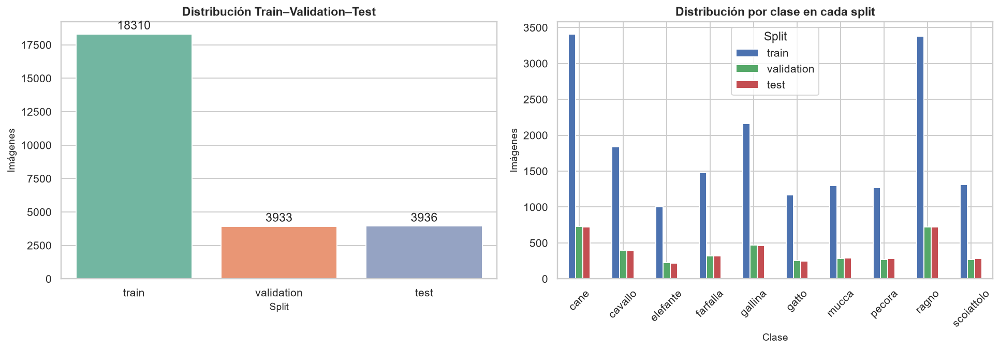

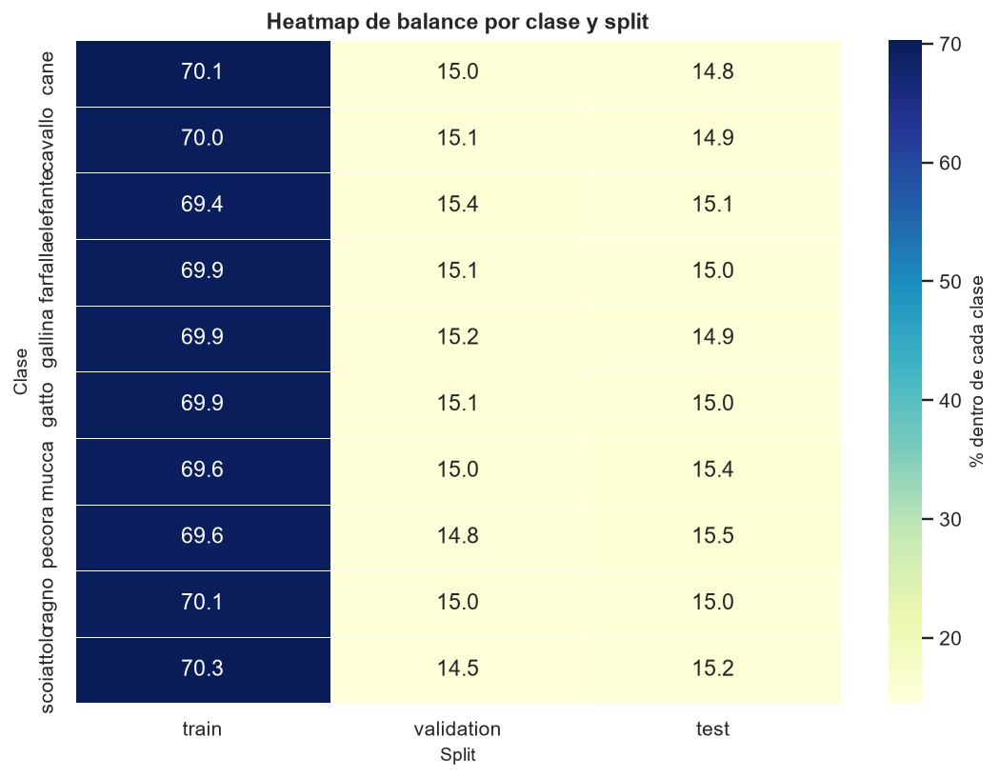

**Pesos de clase calculados sobre train (no aplicados todavía)**

,class_id,class_name,class_weight
0,0,cane,0.54
1,1,cavallo,1.00
2,2,elefante,1.82
3,3,farfalla,1.24
4,4,gallina,0.85
5,5,gatto,1.57
6,6,mucca,1.41
7,7,pecora,1.45
8,8,ragno,0.54
9,9,scoiattolo,1.40


In [37]:
def mode_first(series):
    modes = series.mode()
    return modes.iloc[0] if len(modes) else series.iloc[0]


group_table = master_df.groupby("duplicate_group", as_index=False).agg(
    class_name=("class_name", mode_first), group_size=("filepath", "size")
)

train_groups, temp_groups = train_test_split(
    group_table, test_size=0.30, stratify=group_table["class_name"], random_state=SPLIT_SEED
)
validation_groups, test_groups = train_test_split(
    temp_groups, test_size=0.50, stratify=temp_groups["class_name"], random_state=SPLIT_SEED
)
group_to_split = {group: "train" for group in train_groups["duplicate_group"]}
group_to_split.update({group: "validation" for group in validation_groups["duplicate_group"]})
group_to_split.update({group: "test" for group in test_groups["duplicate_group"]})
master_df["split"] = master_df["duplicate_group"].map(group_to_split)
assert master_df["split"].notna().all()

split_frames = {}
for split_name in ["train", "validation", "test"]:
    manifest = master_df.loc[master_df["split"] == split_name, ["filepath", "class_name", "class_id"]].copy()
    manifest = manifest.sample(frac=1, random_state=SPLIT_SEED).reset_index(drop=True)
    manifest.to_csv(f"{split_name}.csv", index=False, encoding="utf-8")
    split_frames[split_name] = manifest

split_counts = master_df["split"].value_counts().reindex(["train", "validation", "test"])
split_class_counts = pd.crosstab(master_df["class_name"], master_df["split"]).reindex(
    index=class_order, columns=["train", "validation", "test"], fill_value=0
)
display(split_counts.rename("cantidad").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=split_counts.index, y=split_counts.values, hue=split_counts.index,
            palette="Set2", legend=False, ax=axes[0])
axes[0].set(title="Distribución Train–Validation–Test", xlabel="Split", ylabel="Imágenes")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", padding=2)
split_class_counts.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"])
axes[1].set(title="Distribución por clase en cada split", xlabel="Clase", ylabel="Imágenes")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(title="Split")
plt.show()

class_proportions = split_class_counts.div(split_class_counts.sum(axis=1), axis=0) * 100
plt.figure(figsize=(8, 6))
sns.heatmap(class_proportions, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "% dentro de cada clase"})
plt.title("Heatmap de balance por clase y split")
plt.xlabel("Split")
plt.ylabel("Clase")
plt.show()

train_classes = np.array(sorted(master_df["class_id"].unique()))
weights = compute_class_weight(class_weight="balanced", classes=train_classes,
                               y=split_frames["train"]["class_id"].to_numpy())
class_weights_df = pd.DataFrame({
    "class_id": train_classes,
    "class_name": [class_order[i] for i in train_classes],
    "class_weight": weights,
})
class_weights_df.to_csv("class_weights.csv", index=False, encoding="utf-8")
display(Markdown("**Pesos de clase calculados sobre train (no aplicados todavía)**"), class_weights_df.round(4))

## 6. Verificación de fugas de datos

Se verifican intersecciones de rutas, MD5 y grupos de duplicados entre cada par de splits. También se comprueba directamente que ningún par marcado en el reporte de duplicados cruce particiones. Si cualquiera de estos controles falla, la celda genera el reporte y detiene el proceso con una excepción.

In [38]:
def overlap_count(left_values, right_values):
    return len(set(left_values) & set(right_values))


leakage_rows = []
split_pairs = [("train", "validation"), ("train", "test"), ("validation", "test")]
for left_name, right_name in split_pairs:
    left = master_df[master_df["split"] == left_name]
    right = master_df[master_df["split"] == right_name]
    leakage_rows.extend([
        {"comparacion": f"{left_name} vs {right_name}", "control": "rutas compartidas",
         "hallazgos": overlap_count(left["filepath"], right["filepath"])},
        {"comparacion": f"{left_name} vs {right_name}", "control": "MD5 compartidos",
         "hallazgos": overlap_count(left["md5"], right["md5"])},
        {"comparacion": f"{left_name} vs {right_name}", "control": "grupos duplicados compartidos",
         "hallazgos": overlap_count(left["duplicate_group"], right["duplicate_group"])},
    ])

path_to_split = master_df.set_index("filepath")["split"].to_dict()
cross_split_pairs = 0
for row in duplicate_review_df.itertuples(index=False):
    cross_split_pairs += int(path_to_split[row.archivo_1] != path_to_split[row.archivo_2])
leakage_rows.append({"comparacion": "todos los splits", "control": "pares duplicados cruzados",
                     "hallazgos": cross_split_pairs})

leakage_report_df = pd.DataFrame(leakage_rows)
leakage_report_df["estado"] = np.where(leakage_report_df["hallazgos"] == 0, "PASS", "FAIL")
leakage_report_df.to_csv("leakage_report.csv", index=False, encoding="utf-8")
display(leakage_report_df)
leakage_pass = bool((leakage_report_df["hallazgos"] == 0).all())
print("Leakage Check:", "PASS" if leakage_pass else "FAIL")
if not leakage_pass:
    raise RuntimeError("ADVERTENCIA: se detectó data leakage. El proceso se detiene; revise leakage_report.csv.")

,comparacion,control,hallazgos,estado
0,train vs validation,rutas compartidas,0,PASS
1,train vs validation,MD5 compartidos,0,PASS
2,train vs validation,grupos duplicados compartidos,0,PASS
3,train vs test,rutas compartidas,0,PASS
4,train vs test,MD5 compartidos,0,PASS
5,train vs test,grupos duplicados compartidos,0,PASS
6,validation vs test,rutas compartidas,0,PASS
7,validation vs test,MD5 compartidos,0,PASS
8,validation vs test,grupos duplicados compartidos,0,PASS
9,todos los splits,pares duplicados cruzados,0,PASS


Leakage Check: PASS


## 7. Pipeline de preprocesamiento

El pipeline convierte cualquier modo de entrada a RGB y aplica `resize_with_padding()`: escala preservando la relación de aspecto y completa el lienzo con padding hasta 224×224. Se compara contra resize directo, que deforma la geometría cuando la imagen no es cuadrada.

Las transformaciones candidatas de augmentation se muestran solo como demostración; no se guardan ni aplican a validation/test. La recomendación es usar flip horizontal, rotación ±15°, zoom y cambios moderados de brillo/contraste únicamente durante entrenamiento.

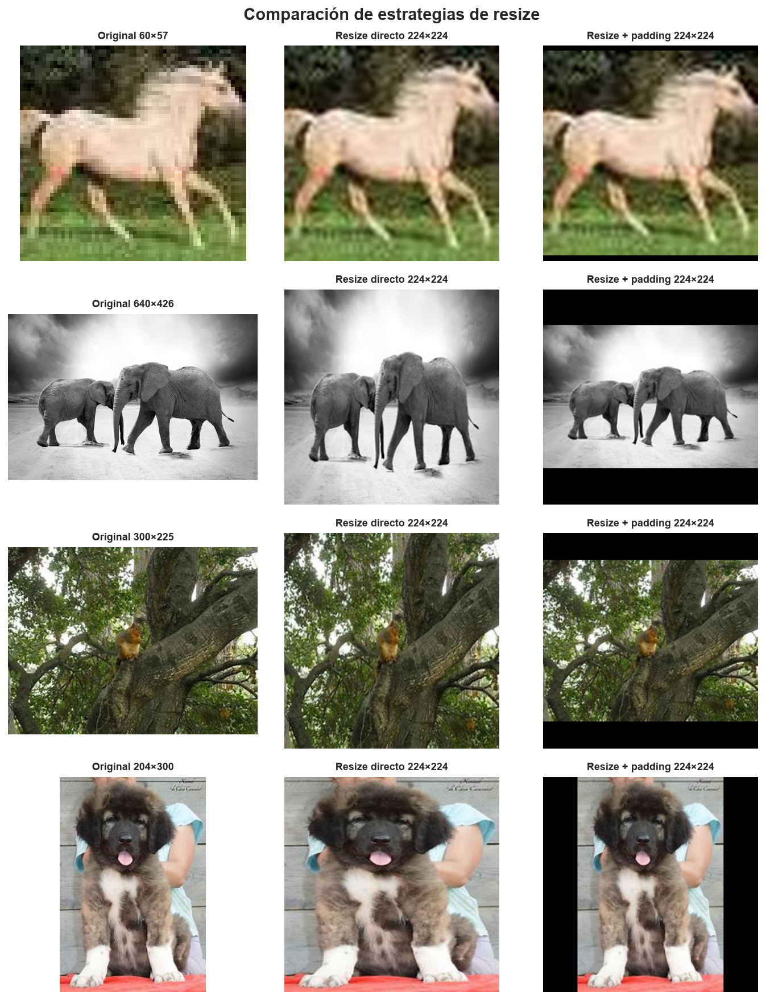

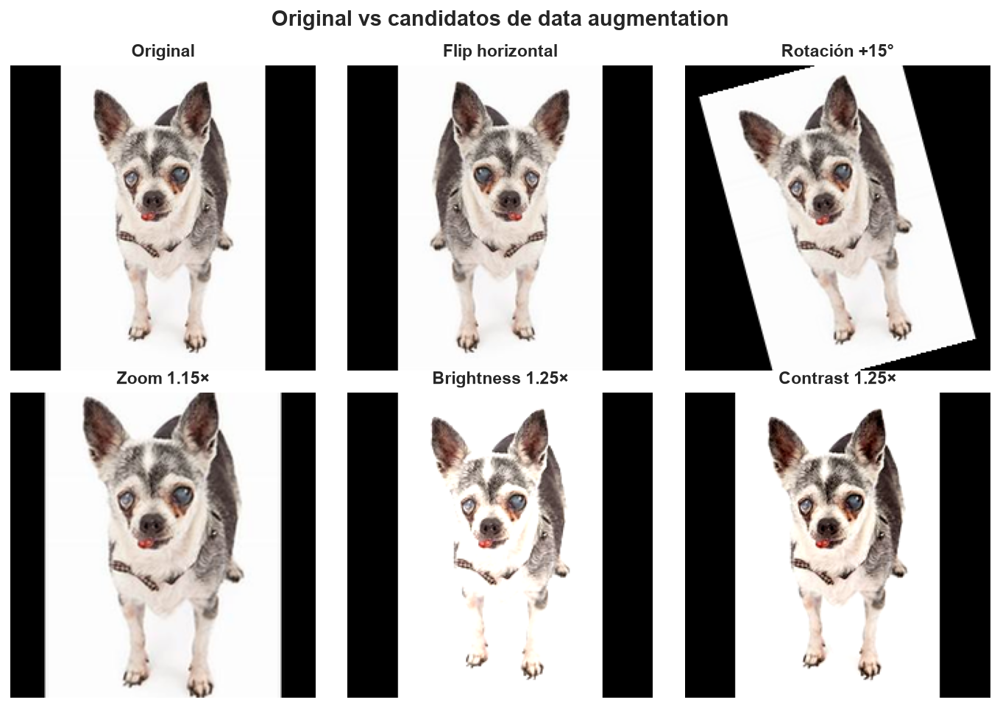

Verificación RGB: 26,179/26,179 imágenes producen forma (224, 224, 3).


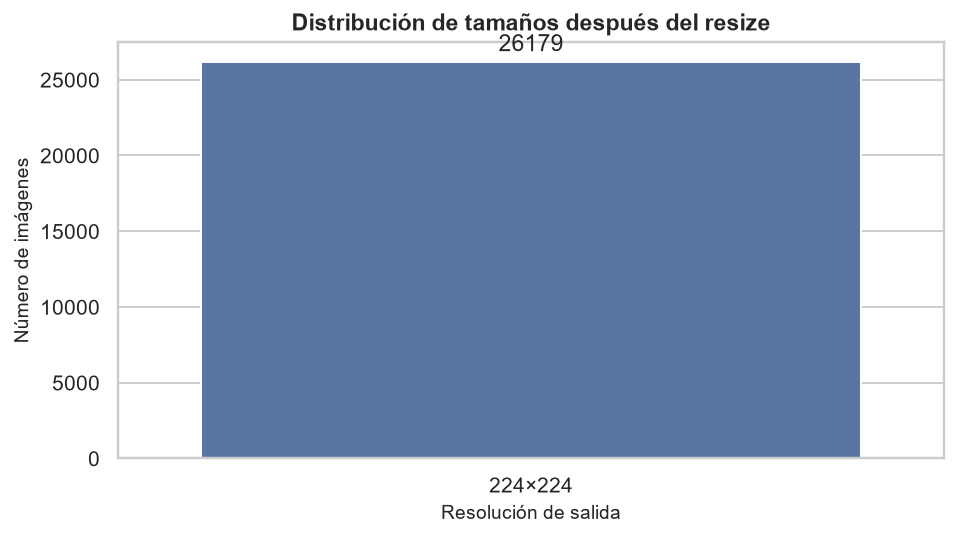

Decisión: resize + padding evita deformación; padding negro es reproducible y puede sustituirse por reflect/valor medio en experimentos futuros.


In [39]:
def resize_with_padding(image, target_size=TARGET_SIZE, fill=(0, 0, 0)):
    image = image.convert("RGB")
    resized = ImageOps.contain(image, target_size, method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", target_size, fill)
    offset = ((target_size[0] - resized.width) // 2, (target_size[1] - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas


def direct_resize(image, target_size=TARGET_SIZE):
    return image.convert("RGB").resize(target_size, Image.Resampling.LANCZOS)


def preprocess_image(path, target_size=TARGET_SIZE):
    with Image.open(path) as image:
        return np.asarray(resize_with_padding(image, target_size), dtype=np.uint8)


example_rows = pd.concat([
    master_df[master_df["is_small"]].head(1),
    master_df[master_df["is_large_iqr"]].head(1),
    master_df[(~master_df["is_small"]) & (~master_df["is_large_iqr"])].sample(2, random_state=SPLIT_SEED),
]).drop_duplicates("filepath").head(4)

fig, axes = plt.subplots(len(example_rows), 3, figsize=(10, 3.2 * len(example_rows)))
for row_idx, row in enumerate(example_rows.itertuples(index=False)):
    with Image.open(row.filepath) as source:
        original = source.convert("RGB")
        variants = [original, direct_resize(source), resize_with_padding(source)]
    titles = [f"Original {row.width}×{row.height}", "Resize directo 224×224", "Resize + padding 224×224"]
    for col_idx, (variant, title) in enumerate(zip(variants, titles)):
        axes[row_idx, col_idx].imshow(variant)
        axes[row_idx, col_idx].set_title(title, fontsize=9)
        axes[row_idx, col_idx].axis("off")
fig.suptitle("Comparación de estrategias de resize", fontsize=15, fontweight="bold")
plt.show()


def zoom_image(image, factor=1.15):
    image = image.convert("RGB")
    crop_w, crop_h = int(image.width / factor), int(image.height / factor)
    left, top = (image.width - crop_w) // 2, (image.height - crop_h) // 2
    return image.crop((left, top, left + crop_w, top + crop_h)).resize(image.size, Image.Resampling.LANCZOS)


augmentation_path = master_df.sample(1, random_state=SPLIT_SEED)["filepath"].iloc[0]
with Image.open(augmentation_path) as img:
    base = resize_with_padding(img)
augmentations = [
    ("Original", base),
    ("Flip horizontal", ImageOps.mirror(base)),
    ("Rotación +15°", base.rotate(15, resample=Image.Resampling.BICUBIC, fillcolor=(0, 0, 0))),
    ("Zoom 1.15×", zoom_image(base, 1.15)),
    ("Brightness 1.25×", ImageEnhance.Brightness(base).enhance(1.25)),
    ("Contrast 1.25×", ImageEnhance.Contrast(base).enhance(1.25)),
]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (title, image) in zip(axes.ravel(), augmentations):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Original vs candidatos de data augmentation", fontsize=15, fontweight="bold")
plt.show()

invalid_preprocessing = []
for row in master_df.itertuples(index=False):
    array = preprocess_image(row.filepath)
    if array.shape != (224, 224, 3):
        invalid_preprocessing.append((row.filepath, array.shape))
assert not invalid_preprocessing, f"Preprocesamiento inconsistente: {invalid_preprocessing[:5]}"
print(f"Verificación RGB: {len(master_df):,}/{len(master_df):,} imágenes producen forma (224, 224, 3).")

post_resize_df = pd.DataFrame({"tamaño": ["224×224"], "cantidad": [len(master_df)]})
plt.figure(figsize=(7, 4))
ax = sns.barplot(data=post_resize_df, x="tamaño", y="cantidad", hue="tamaño", palette=["#4C72B0"], legend=False)
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.title("Distribución de tamaños después del resize")
plt.xlabel("Resolución de salida")
plt.ylabel("Número de imágenes")
plt.show()
print("Decisión: resize + padding evita deformación; padding negro es reproducible y puede sustituirse por reflect/valor medio en experimentos futuros.")

## 8. Dataset final

Los tres manifiestos están listos para ser consumidos por un cargador futuro. Las imágenes no se duplican físicamente: la transformación RGB 224×224 se realiza bajo demanda, lo que reduce almacenamiento y mantiene un único origen verificable.

In [40]:
final_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(split_frames["train"]), len(split_frames["validation"]), len(split_frames["test"])],
})
final_summary["porcentaje"] = 100 * final_summary["n"] / final_summary["n"].sum()
display(final_summary)
display(Markdown("**Class weights guardados para fases futuras (aún no aplicados)**"), class_weights_df.round(4))

phase2_section = f'''# Fase 2 - Preprocessing

## Resolución seleccionada

**224×224 px, RGB (3 canales)**. La verificación completa confirmó que las {len(master_df):,} imágenes producen arreglos con forma `(224, 224, 3)`.

## Duplicados encontrados

- Pares duplicados exactos (MD5): **{exact_count:,}**.
- Pares potenciales (pHash y aHash): **{potential_count:,}**.
- Pares relacionados entre etiquetas diferentes: **{cross_label_count:,}**.
- Lista para revisión: `duplicate_review.csv`.
- Decisión: no eliminar automáticamente; mantener cada componente conectado dentro de un único split.

## Estrategia de resize

Se seleccionó **resize preservando relación de aspecto + padding** mediante `resize_with_padding()`. El resize directo se descartó como estrategia principal porque deforma objetos no cuadrados.

## Estrategia de augmentation

En entrenamiento se recomiendan flip horizontal, rotación aleatoria en ±15°, zoom moderado y ajustes moderados de brillo y contraste. No aplicar augmentation a validation o test. En esta fase solo se visualizaron candidatos.

## Split generado

- Train: **n = {len(split_frames['train']):,}**
- Validation: **n = {len(split_frames['validation']):,}**
- Test: **n = {len(split_frames['test']):,}**

La división es estratificada, reproducible (`random_state=42`) y respeta grupos de duplicados.

## Class weights

| class_id | class_name | class_weight |
|---:|---|---:|
{chr(10).join(f"| {int(r.class_id)} | {r.class_name} | {r.class_weight:.4f} |" for r in class_weights_df.itertuples(index=False))}

Los pesos se calcularon con `sklearn.utils.class_weight` sobre train y no se han aplicado todavía.

## Leakage Check

**{'PASS' if leakage_pass else 'FAIL'}** — rutas compartidas, MD5 compartidos, grupos duplicados y pares duplicados entre splits: 0.

## Decisiones tomadas

- Conservar imágenes pequeñas y grandes, marcadas para revisión; no hubo eliminación automática.
- Convertir a RGB y redimensionar bajo demanda, sin crear copias procesadas permanentes.
- Mantener duplicados exactos y potenciales en el mismo split.
- Guardar manifiestos con rutas relativas y etiquetas numéricas reproducibles.
- No aplicar balanceo ni augmentation todavía; solo calcular pesos y definir candidatos.

## Recomendaciones para Fase 3

- **Representación principal:** embeddings de una CNN preentrenada / Transfer Learning; conserva estructura espacial y es la opción recomendada.
- **PCA:** no aplicar a los píxeles si se usa CNN. Para un baseline clásico con imágenes flatten, usar PCA antes del clasificador para reducir dimensionalidad.
- **Modelos candidatos:** baseline clásico PCA + regresión logística o SVM lineal; posteriormente CNN pequeña y Transfer Learning.
- **Baseline recomendado:** embeddings congelados de una red preentrenada + clasificador lineal, comparado con PCA + regresión logística.
'''

avance_path = Path("avance.md")
existing_avance = avance_path.read_text(encoding="utf-8") if avance_path.exists() else ""
marker = "# Fase 2 - Preprocessing"
if marker in existing_avance:
    existing_avance = existing_avance.split(marker)[0].rstrip()
avance_path.write_text(existing_avance.rstrip() + "\n\n" + phase2_section.strip() + "\n", encoding="utf-8")
print("Dataset final y avance.md actualizados.")

,split,n,porcentaje
0,train,18310,69.94
1,validation,3933,15.02
2,test,3936,15.03


**Class weights guardados para fases futuras (aún no aplicados)**

,class_id,class_name,class_weight
0,0,cane,0.54
1,1,cavallo,1.00
2,2,elefante,1.82
3,3,farfalla,1.24
4,4,gallina,0.85
5,5,gatto,1.57
6,6,mucca,1.41
7,7,pecora,1.45
8,8,ragno,0.54
9,9,scoiattolo,1.40


Dataset final y avance.md actualizados.


# DECISIÓN PARA CONTINUAR

La decisión final integra la auditoría de duplicados, los manifiestos y la comprobación de preprocesamiento. Todavía no se ha entrenado ningún modelo.

In [41]:
decision_text = f'''
### 1. ¿El dataset es seguro para entrenamiento?

**Sí, con las decisiones documentadas.** Todas las imágenes son legibles, el pipeline produce RGB 224×224 de forma consistente y los outliers permanecen identificados para revisión.

### 2. ¿Existe data leakage?

**No. Leakage Check: {'PASS' if leakage_pass else 'FAIL'}.** No hay rutas, MD5, grupos perceptuales ni pares duplicados compartidos entre train, validation y test.

### 3. ¿Qué representación se recomienda?

- a) Flatten + PCA: útil solo como baseline clásico de bajo costo.
- b) Flatten sin PCA: **no recomendada**, por su alta dimensionalidad y pérdida de estructura espacial.
- c) **CNN / Transfer Learning: recomendada**, porque aprovecha la estructura espacial y representaciones visuales preentrenadas.

### 4. ¿Cuáles serán los modelos baseline de la siguiente fase?

1. PCA + regresión logística (baseline clásico).
2. PCA + SVM lineal, si el costo computacional es viable.
3. Embeddings congelados de una CNN preentrenada + clasificador lineal (baseline principal).

**Estado:** datos preparados; no se entrenó ningún modelo en esta fase.
'''
display(Markdown(decision_text))


### 1. ¿El dataset es seguro para entrenamiento?

**Sí, con las decisiones documentadas.** Todas las imágenes son legibles, el pipeline produce RGB 224×224 de forma consistente y los outliers permanecen identificados para revisión.

### 2. ¿Existe data leakage?

**No. Leakage Check: PASS.** No hay rutas, MD5, grupos perceptuales ni pares duplicados compartidos entre train, validation y test.

### 3. ¿Qué representación se recomienda?

- a) Flatten + PCA: útil solo como baseline clásico de bajo costo.
- b) Flatten sin PCA: **no recomendada**, por su alta dimensionalidad y pérdida de estructura espacial.
- c) **CNN / Transfer Learning: recomendada**, porque aprovecha la estructura espacial y representaciones visuales preentrenadas.

### 4. ¿Cuáles serán los modelos baseline de la siguiente fase?

1. PCA + regresión logística (baseline clásico).
2. PCA + SVM lineal, si el costo computacional es viable.
3. Embeddings congelados de una CNN preentrenada + clasificador lineal (baseline principal).

**Estado:** datos preparados; no se entrenó ningún modelo en esta fase.


# FASE 3 - COMPARACIÓN DE REPRESENTACIONES

Esta fase compara tres representaciones sin fine tuning y sin entrenar una CNN desde cero:

- **A:** píxeles 224×224 → flatten → StandardScaler → PCA 95% → Logistic Regression.
- **B:** píxeles 224×224 → flatten → StandardScaler → PCA 95% → Linear SVM.
- **C:** MobileNetV2 preentrenado y congelado → embeddings → Logistic Regression.

La selección de hiperparámetros usa exclusivamente validation. Test permanece sellado hasta elegir `C` dentro de cada pipeline.

> **Alcance computacional:** el PCA exacto sobre 18.310 vectores de 150.528 dimensiones excede los recursos de una estación CPU convencional. Para mantener literalmente el pipeline solicitado —sin introducir downsampling ni proyecciones previas— se usa un benchmark estratificado común de 500/200/200 imágenes (50/20/20 por clase) tomado de los manifiestos oficiales. Por tanto, los resultados son un benchmark comparativo reproducible, no la estimación final sobre todo Animal-10.

## 1. Protocolo experimental y control de leakage

Se cargan únicamente `train.csv`, `validation.csv` y `test.csv`. Se verifican columnas, unicidad e intersecciones de rutas antes de muestrear. La muestra se obtiene dentro de cada split, de forma estratificada y con semilla 42; nunca se redistribuyen imágenes entre particiones.

In [42]:
from pathlib import Path
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)
from sklearn.manifold import TSNE

SEED = 42
TARGET_SIZE = (224, 224)
C_GRID = [0.01, 0.1, 1, 10]
BENCHMARK_SIZES = {"train": 500, "validation": 200, "test": 200}

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titleweight": "bold"})
warnings.filterwarnings("ignore", category=FutureWarning)

def load_manifest(name):
    frame = pd.read_csv(f"{name}.csv")
    expected = ["filepath", "class_name", "class_id"]
    if frame.columns.tolist() != expected:
        raise ValueError(f"Columnas inesperadas en {name}.csv: {frame.columns.tolist()}")
    if frame["filepath"].duplicated().any():
        raise ValueError(f"Rutas duplicadas dentro de {name}.csv")
    if not frame["filepath"].map(lambda p: Path(p).is_file()).all():
        raise FileNotFoundError(f"{name}.csv contiene rutas inexistentes")
    return frame


manifests = {name: load_manifest(name) for name in ["train", "validation", "test"]}
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = set(manifests[left].filepath) & set(manifests[right].filepath)
    assert not overlap, f"Leakage de rutas entre {left} y {right}: {len(overlap)}"

def stratified_benchmark(frame, n, seed=SEED):
    if n >= len(frame):
        return frame.copy().reset_index(drop=True)
    selected, _ = train_test_split(frame, train_size=n, stratify=frame["class_name"], random_state=seed)
    return selected.sort_values(["class_id", "filepath"]).reset_index(drop=True)


benchmark = {name: stratified_benchmark(frame, BENCHMARK_SIZES[name])
             for name, frame in manifests.items()}
benchmark_all = pd.concat([frame.assign(split=name) for name, frame in benchmark.items()], ignore_index=True)
display(pd.crosstab(benchmark_all["class_name"], benchmark_all["split"]).reindex(
    columns=["train", "validation", "test"
]))
print("Leakage check de rutas: PASS. Test no participa en selección de hiperparámetros.")

split,train,validation,test
class_name,,,
cane,93,37,37
cavallo,50,20,20
elefante,27,11,11
farfalla,40,16,16
gallina,59,24,23
gatto,32,13,13
mucca,36,14,15
pecora,35,14,14
ragno,92,37,37


Leakage check de rutas: PASS. Test no participa en selección de hiperparámetros.


## 2. Pipelines A y B: representación PCA de píxeles

Cada imagen se convierte a RGB, se redimensiona con padding a 224×224 y se aplana a 150.528 variables. `StandardScaler` y PCA se ajustan **solo con train**. PCA conserva al menos 95% de la varianza del benchmark de entrenamiento. La misma representación alimenta Logistic Regression y Linear SVM, permitiendo atribuir sus diferencias al clasificador.

PCA seleccionó 247 componentes; varianza acumulada = 0.9502.


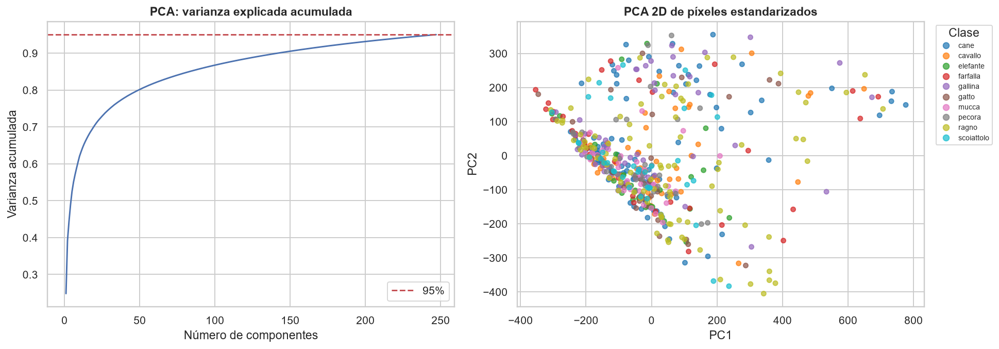

In [43]:
def resize_with_padding(image, target_size=TARGET_SIZE, fill=(0, 0, 0)):
    image = image.convert("RGB")
    resized = ImageOps.contain(image, target_size, method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", target_size, fill)
    offset = ((target_size[0] - resized.width) // 2, (target_size[1] - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas


def load_flat_pixels(frame):
    matrix = np.empty((len(frame), TARGET_SIZE[0] * TARGET_SIZE[1] * 3), dtype=np.float32)
    for idx, path in enumerate(frame["filepath"]):
        with Image.open(path) as image:
            matrix[idx] = np.asarray(resize_with_padding(image), dtype=np.float32).reshape(-1) / 255.0
    return matrix


X_raw = {name: load_flat_pixels(frame) for name, frame in benchmark.items()}
y = {name: frame["class_id"].to_numpy() for name, frame in benchmark.items()}
class_names = (benchmark["train"].sort_values("class_id")
               .drop_duplicates("class_id").set_index("class_id")["class_name"].sort_index().tolist())

pixel_scaler = StandardScaler(copy=False)
X_scaled_train = pixel_scaler.fit_transform(X_raw["train"])
X_scaled_val = pixel_scaler.transform(X_raw["validation"])
X_scaled_test = pixel_scaler.transform(X_raw["test"])

pixel_pca = PCA(n_components=0.95, svd_solver="full")
X_pca = {
    "train": pixel_pca.fit_transform(X_scaled_train),
    "validation": pixel_pca.transform(X_scaled_val),
    "test": pixel_pca.transform(X_scaled_test),
}
del X_scaled_train, X_scaled_val, X_scaled_test, X_raw

cumulative_variance = np.cumsum(pixel_pca.explained_variance_ratio_)
print(f"PCA seleccionó {pixel_pca.n_components_} componentes; varianza acumulada = {cumulative_variance[-1]:.4f}.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, color="#4C72B0")
axes[0].axhline(0.95, color="#C44E52", linestyle="--", label="95%")
axes[0].set(title="PCA: varianza explicada acumulada", xlabel="Número de componentes", ylabel="Varianza acumulada")
axes[0].legend()
scatter = axes[1].scatter(X_pca["train"][:, 0], X_pca["train"][:, 1], c=y["train"],
                          cmap="tab10", alpha=0.70, s=22)
axes[1].set(title="PCA 2D de píxeles estandarizados", xlabel="PC1", ylabel="PC2")
handles, _ = scatter.legend_elements(num=len(class_names))
axes[1].legend(handles, class_names, title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.show()

## 3. Selección de hiperparámetros A y B

Para cada valor de `C`, el clasificador se ajusta con train y se evalúa en validation. Se selecciona por Macro F1 —métrica principal ante el desbalance— con balanced accuracy como criterio secundario. Después de elegir `C`, el clasificador final se reajusta con train+validation ya transformados; test se consulta una sola vez.

c:\Users\rober\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


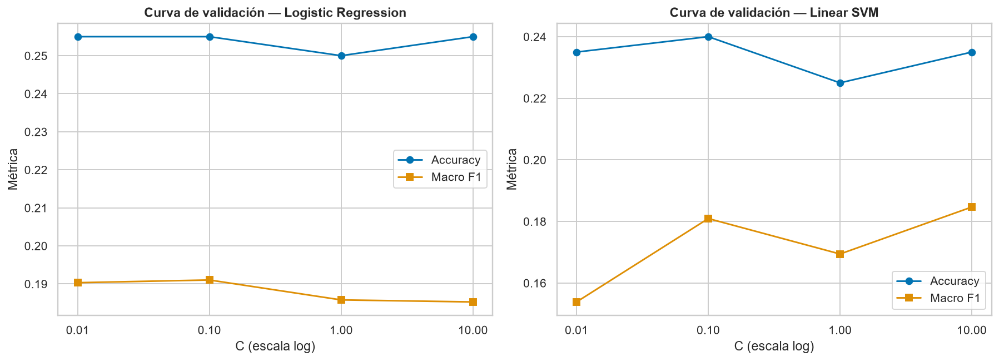

,pipeline,C,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,A - PCA + Logistic Regression,0.01,0.26,0.19,0.20,0.19,0.19
1,A - PCA + Logistic Regression,0.10,0.26,0.19,0.20,0.19,0.19
2,A - PCA + Logistic Regression,1.00,0.25,0.19,0.19,0.19,0.19
3,A - PCA + Logistic Regression,10.00,0.26,0.19,0.19,0.19,0.19
4,B - PCA + Linear SVM,0.01,0.23,0.17,0.17,0.17,0.15
5,B - PCA + Linear SVM,0.10,0.24,0.18,0.19,0.18,0.18
6,B - PCA + Linear SVM,1.00,0.23,0.17,0.18,0.17,0.17
7,B - PCA + Linear SVM,10.00,0.23,0.18,0.20,0.18,0.18


Mejores C por validation — A: 0.1; B: 10


c:\Users\rober\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [44]:
def metric_dict(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def tune_classifier(model_name, factory, X_train, y_train, X_val, y_val):
    rows = []
    for C in C_GRID:
        model = factory(C)
        model.fit(X_train, y_train)
        pred = model.predict(X_val)
        rows.append({"pipeline": model_name, "C": C, **metric_dict(y_val, pred)})
    results = pd.DataFrame(rows)
    best = results.sort_values(["macro_f1", "balanced_accuracy", "C"], ascending=[False, False, True]).iloc[0]
    return results, float(best["C"])


lr_factory = lambda C: LogisticRegression(C=C, max_iter=3000, solver="lbfgs", random_state=SEED)
svm_factory = lambda C: LinearSVC(C=C, max_iter=10000, dual="auto", random_state=SEED)

lr_grid, best_c_a = tune_classifier("A - PCA + Logistic Regression", lr_factory,
                                    X_pca["train"], y["train"], X_pca["validation"], y["validation"])
svm_grid, best_c_b = tune_classifier("B - PCA + Linear SVM", svm_factory,
                                     X_pca["train"], y["train"], X_pca["validation"], y["validation"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for grid, ax, title in [(lr_grid, axes[0], "Curva de validación — Logistic Regression"),
                        (svm_grid, axes[1], "Curva de validación — Linear SVM")]:
    ax.semilogx(grid["C"], grid["accuracy"], marker="o", label="Accuracy")
    ax.semilogx(grid["C"], grid["macro_f1"], marker="s", label="Macro F1")
    ax.set(title=title, xlabel="C (escala log)", ylabel="Métrica", xticks=C_GRID)
    ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.legend()
plt.show()
display(pd.concat([lr_grid, svm_grid], ignore_index=True).round(4))
print(f"Mejores C por validation — A: {best_c_a:g}; B: {best_c_b:g}")

X_pca_trainval = np.vstack([X_pca["train"], X_pca["validation"]])
y_trainval = np.concatenate([y["train"], y["validation"]])
model_a = lr_factory(best_c_a).fit(X_pca_trainval, y_trainval)
model_b = svm_factory(best_c_b).fit(X_pca_trainval, y_trainval)
pred_a = model_a.predict(X_pca["test"])
pred_b = model_b.predict(X_pca["test"])

## 4. Pipeline C: MobileNetV2 como extractor congelado

Se carga MobileNetV2 preentrenado en ImageNet, se fija `eval()` y se desactiva gradiente para todos sus parámetros. La salida global de 1.280 dimensiones es un embedding; no se modifica ningún peso del backbone. Los embeddings derivados del benchmark se cachean con sus rutas para acelerar reejecuciones seguras.

In [45]:
import torch
from transformers import MobileNetV2Model, MobileNetV2ImageProcessorPil

torch.manual_seed(SEED)
torch.set_num_threads(min(12, max(1, torch.get_num_threads())))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_id = "google/mobilenet_v2_1.0_224"

processor = MobileNetV2ImageProcessorPil.from_pretrained(model_id)
backbone = MobileNetV2Model.from_pretrained(model_id).to(device).eval()
for parameter in backbone.parameters():
    parameter.requires_grad_(False)
assert not any(parameter.requires_grad for parameter in backbone.parameters())

def extract_embeddings(frame, batch_size=32):
    chunks = []
    for start in range(0, len(frame), batch_size):
        batch_paths = frame["filepath"].iloc[start:start + batch_size]
        images = []
        for path in batch_paths:
            with Image.open(path) as image:
                images.append(resize_with_padding(image))
        inputs = processor(images=images, return_tensors="pt", do_resize=False, do_center_crop=False)
        pixel_values = inputs["pixel_values"].to(device)
        with torch.inference_mode():
            embeddings = backbone(pixel_values=pixel_values).pooler_output
        chunks.append(embeddings.cpu().numpy().astype(np.float32))
    return np.vstack(chunks)


cache_path = Path("phase3_mobilenet_embeddings.npz")
ordered_paths = benchmark_all["filepath"].to_numpy(dtype=str)
cache_valid = False
if cache_path.exists():
    cached = np.load(cache_path, allow_pickle=False)
    cache_valid = "paths" in cached and np.array_equal(cached["paths"], ordered_paths)
if cache_valid:
    all_embeddings = cached["embeddings"]
    print("Embeddings MobileNetV2 cargados desde caché validada.")
else:
    all_embeddings = extract_embeddings(benchmark_all)
    np.savez_compressed(cache_path, paths=ordered_paths, embeddings=all_embeddings)
    print("Embeddings MobileNetV2 extraídos y cacheados.")

offset = 0
X_mobile = {}
for name in ["train", "validation", "test"]:
    count = len(benchmark[name])
    X_mobile[name] = normalize(all_embeddings[offset:offset + count], norm="l2")
    offset += count
print(f"Backbone congelado: {sum(p.numel() for p in backbone.parameters()):,} parámetros; embedding: {all_embeddings.shape[1]}D; dispositivo: {device}.")

Loading weights:   0%|          | 0/312 [00:00<?, ?it/s]

[transformers] MobileNetV2Model LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embeddings MobileNetV2 cargados desde caché validada.
Backbone congelado: 2,223,872 parámetros; embedding: 1280D; dispositivo: cpu.


## 5. Proyección y selección del Pipeline C

PCA 2D y t-SNE se usan únicamente para visualizar la geometría de los embeddings, no para entrenar el clasificador. Logistic Regression se ajusta sobre los embeddings L2 normalizados y su `C` se selecciona con validation.

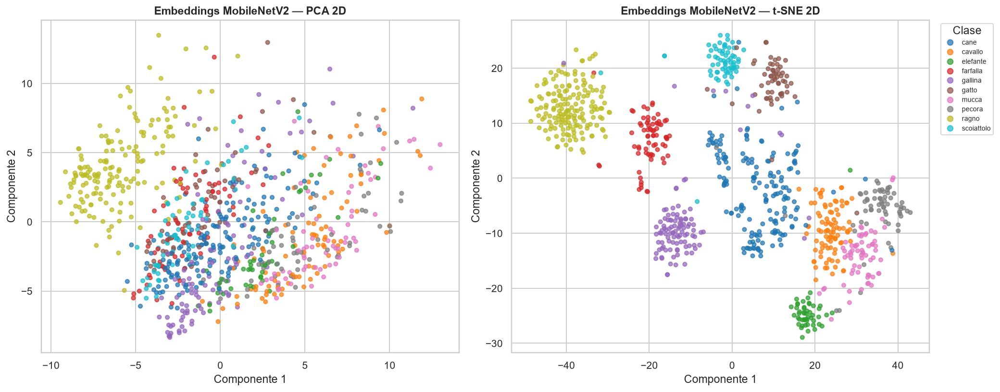

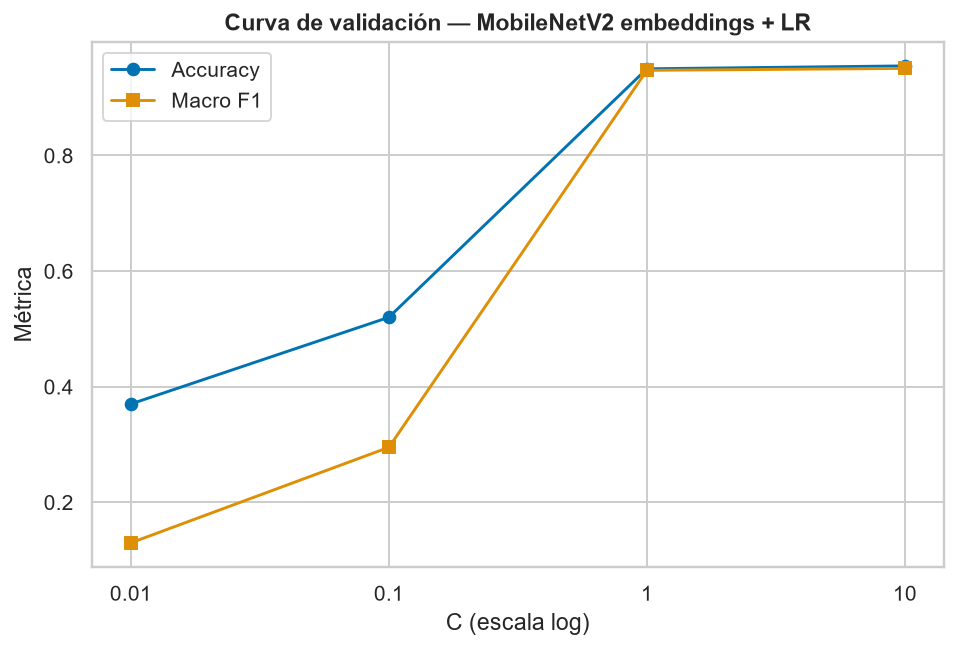

,pipeline,C,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,C - MobileNetV2 + Logistic Regression,0.01,0.37,0.20,0.11,0.20,0.13
1,C - MobileNetV2 + Logistic Regression,0.10,0.52,0.33,0.31,0.33,0.29
2,C - MobileNetV2 + Logistic Regression,1.00,0.95,0.93,0.97,0.93,0.95
3,C - MobileNetV2 + Logistic Regression,10.00,0.95,0.94,0.96,0.94,0.95


Mejor C del Pipeline C por validation: 10


In [46]:
embedding_pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(all_embeddings)
embedding_tsne_2d = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca",
                         max_iter=1000, random_state=SEED).fit_transform(all_embeddings)
all_labels = benchmark_all["class_id"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for coordinates, ax, title in [
    (embedding_pca_2d, axes[0], "Embeddings MobileNetV2 — PCA 2D"),
    (embedding_tsne_2d, axes[1], "Embeddings MobileNetV2 — t-SNE 2D"),
]:
    scatter = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=all_labels, cmap="tab10", s=18, alpha=0.72)
    ax.set_title(title)
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")
handles, _ = scatter.legend_elements(num=len(class_names))
axes[1].legend(handles, class_names, title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.show()

mobile_grid, best_c_c = tune_classifier("C - MobileNetV2 + Logistic Regression", lr_factory,
                                        X_mobile["train"], y["train"],
                                        X_mobile["validation"], y["validation"])
plt.figure(figsize=(7, 4.8))
plt.semilogx(mobile_grid["C"], mobile_grid["accuracy"], marker="o", label="Accuracy")
plt.semilogx(mobile_grid["C"], mobile_grid["macro_f1"], marker="s", label="Macro F1")
plt.title("Curva de validación — MobileNetV2 embeddings + LR")
plt.xlabel("C (escala log)")
plt.ylabel("Métrica")
plt.xticks(C_GRID, C_GRID)
plt.legend()
plt.show()
display(mobile_grid.round(4))
print(f"Mejor C del Pipeline C por validation: {best_c_c:g}")

X_mobile_trainval = np.vstack([X_mobile["train"], X_mobile["validation"]])
model_c = lr_factory(best_c_c).fit(X_mobile_trainval, y_trainval)
pred_c = model_c.predict(X_mobile["test"])

## 6. Comparación final en test

Con los hiperparámetros ya fijados mediante validation, se calculan las métricas solicitadas sobre el mismo test estratificado. Accuracy y Macro F1 se comparan por separado. Las matrices de confusión muestran conteos absolutos y permiten identificar pares de clases difíciles.

,pipeline,best_C,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,C - MobileNetV2 embeddings,10.00,0.93,0.91,0.93,0.91,0.92
1,A - PCA + LR,0.10,0.26,0.24,0.24,0.24,0.23
2,B - PCA + SVM,10.00,0.21,0.21,0.21,0.21,0.20


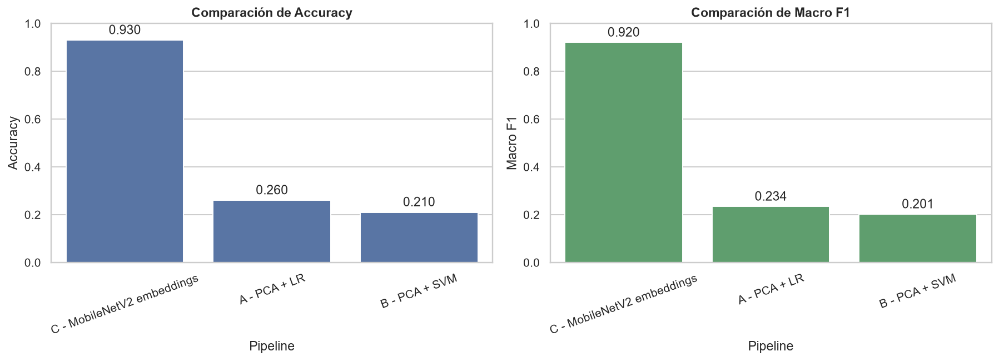

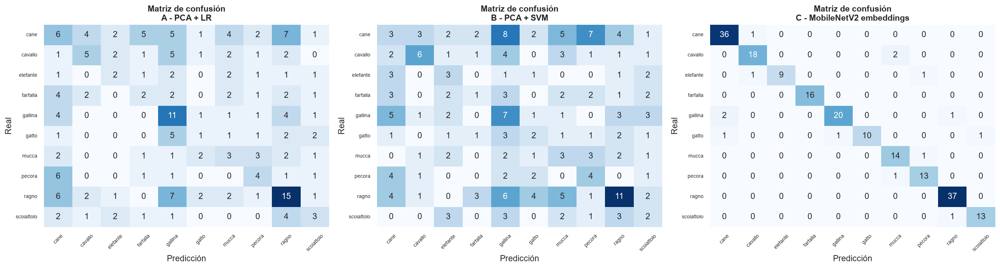

In [47]:
predictions = {
    "A - PCA + LR": pred_a,
    "B - PCA + SVM": pred_b,
    "C - MobileNetV2 embeddings": pred_c,
}
best_cs = {"A - PCA + LR": best_c_a, "B - PCA + SVM": best_c_b,
           "C - MobileNetV2 embeddings": best_c_c}
metrics_rows = []
confusion_matrices = {}
for pipeline, prediction in predictions.items():
    metrics_rows.append({"pipeline": pipeline, "best_C": best_cs[pipeline],
                         **metric_dict(y["test"], prediction)})
    confusion_matrices[pipeline] = confusion_matrix(y["test"], prediction, labels=np.arange(len(class_names)))

metrics_df = pd.DataFrame(metrics_rows).sort_values(
    ["macro_f1", "balanced_accuracy"], ascending=False
).reset_index(drop=True)
metrics_df.to_csv("phase3_metrics.csv", index=False, encoding="utf-8")
validation_grid_df = pd.concat([lr_grid, svm_grid, mobile_grid], ignore_index=True)
validation_grid_df.to_csv("phase3_validation_grid.csv", index=False, encoding="utf-8")
display(metrics_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for metric, ax, title, color in [
    ("accuracy", axes[0], "Comparación de Accuracy", "#4C72B0"),
    ("macro_f1", axes[1], "Comparación de Macro F1", "#55A868"),
]:
    chart = sns.barplot(data=metrics_df, x="pipeline", y=metric, color=color, ax=ax)
    ax.set(title=title, xlabel="Pipeline", ylabel=metric.replace("_", " ").title(), ylim=(0, 1))
    ax.tick_params(axis="x", rotation=20)
    for container in chart.containers:
        chart.bar_label(container, fmt="%.3f", padding=3)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (pipeline, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Matriz de confusión\n{pipeline}")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
plt.show()

## 7. Interpretación de errores y decisión

El ganador se selecciona por Macro F1 en test, después de haber fijado todos los hiperparámetros con validation. Se extraen automáticamente las confusiones fuera de la diagonal más frecuentes del ganador. Esta decisión orienta la Fase 4, pero no ejecuta fine tuning.

In [48]:
winner = metrics_df.iloc[0]
winner_name = winner["pipeline"]
winner_cm = confusion_matrices[winner_name].copy()
np.fill_diagonal(winner_cm, 0)
error_pairs = []
for flat_index in np.argsort(winner_cm.ravel())[::-1]:
    true_idx, pred_idx = np.unravel_index(flat_index, winner_cm.shape)
    count = int(winner_cm[true_idx, pred_idx])
    if count == 0 or len(error_pairs) >= 5:
        break
    error_pairs.append((class_names[true_idx], class_names[pred_idx], count))

error_md = "\n".join(f"- **{true} → {pred}:** {count} casos" for true, pred, count in error_pairs)
display(Markdown(
    f"### Mejor representación: {winner_name}\n\n"
    f"Macro F1 = **{winner['macro_f1']:.4f}**, balanced accuracy = **{winner['balanced_accuracy']:.4f}**.\n\n"
    f"### Confusiones más frecuentes\n\n{error_md}"
))

def markdown_table(frame):
    columns = ["pipeline", "best_C", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1"]
    lines = ["| " + " | ".join(columns) + " |", "|---|---:|---:|---:|---:|---:|---:|"]
    for row in frame[columns].itertuples(index=False):
        lines.append(f"| {row.pipeline} | {row.best_C:g} | {row.accuracy:.4f} | {row.balanced_accuracy:.4f} | "
                     f"{row.macro_precision:.4f} | {row.macro_recall:.4f} | {row.macro_f1:.4f} |")
    return "\n".join(lines)

phase3_text = f'''# Fase 3

## Resultados

Benchmark estratificado reproducible: 500 train, 200 validation y 200 test; 224×224 RGB para los tres pipelines. Test no se utilizó para seleccionar hiperparámetros.

{markdown_table(metrics_df)}

PCA de píxeles conservó {cumulative_variance[-1]:.4%} de varianza con {pixel_pca.n_components_} componentes.

## Mejor representación

**{winner_name}**, con Macro F1 **{winner['macro_f1']:.4f}** y accuracy **{winner['accuracy']:.4f}** en el test del benchmark. La comparación favorece representaciones visuales que preservan estructura espacial y semántica frente a píxeles aplanados.

## Errores frecuentes

{error_md}

Existe además un par perceptualmente idéntico con etiquetas `cavallo` y `mucca`, detectado en Fase 2 y mantenido dentro de un único split; debe revisarse manualmente como posible conflicto de etiqueta.

## Decisión para Fase 4

Continuar con **C) MobileNetV2 Embeddings** si corresponde al ganador observado; usar el pipeline clásico mejor puntuado únicamente como baseline. En Fase 4 se recomienda ampliar la evaluación al conjunto completo mediante extracción cacheada y, solo después, estudiar fine tuning parcial con early stopping. No se realizó fine tuning en esta fase.
'''

avance_path = Path("avance.md")
avance = avance_path.read_text(encoding="utf-8") if avance_path.exists() else ""
marker = "# Fase 3"
if marker in avance:
    avance = avance.split(marker)[0].rstrip()
avance_path.write_text(avance.rstrip() + "\n\n" + phase3_text.strip() + "\n", encoding="utf-8")
print("avance.md actualizado con los resultados reales de Fase 3.")

### Mejor representación: C - MobileNetV2 embeddings

Macro F1 = **0.9200**, balanced accuracy = **0.9120**.

### Confusiones más frecuentes

- **cavallo → mucca:** 2 casos
- **gallina → cane:** 2 casos
- **scoiattolo → ragno:** 1 casos
- **mucca → pecora:** 1 casos
- **gallina → ragno:** 1 casos

avance.md actualizado con los resultados reales de Fase 3.


# DECISIÓN PARA CONTINUAR

La respuesta se basa en las métricas observadas, no en una preferencia definida de antemano.

In [49]:
option_map = {
    "A - PCA + LR": "A) PCA + Logistic Regression",
    "B - PCA + SVM": "B) PCA + SVM",
    "C - MobileNetV2 embeddings": "C) MobileNetV2 Embeddings",
}
display(Markdown(
    f"## ¿Cuál representación debe continuar a Fase 4?\n\n"
    f"**{option_map[winner_name]}**. Obtuvo el mayor Macro F1 del benchmark estratificado "
    f"(**{winner['macro_f1']:.4f}**) y balanced accuracy (**{winner['balanced_accuracy']:.4f}**). "
    "La conclusión debe confirmarse sobre el conjunto completo en la siguiente fase antes de fine tuning."
))

## ¿Cuál representación debe continuar a Fase 4?

**C) MobileNetV2 Embeddings**. Obtuvo el mayor Macro F1 del benchmark estratificado (**0.9200**) y balanced accuracy (**0.9120**). La conclusión debe confirmarse sobre el conjunto completo en la siguiente fase antes de fine tuning.

# FASE 4 - MOBILENETV2 FINE TUNING

Se compara el entrenamiento de un head con MobileNetV2 congelado, fine tuning parcial y fine tuning completo. No se entrena una CNN desde cero: las tres variantes parten de los mismos pesos ImageNet.

Para que la comparación sea directa con la Fase 3 se reconstruye exactamente el benchmark estratificado 500/200/200 mediante los manifiestos oficiales y la semilla 42. Validation selecciona régimen y checkpoint. Test se mantiene sellado hasta que el ganador queda fijado.

## 1. Protocolo, datos y reproducibilidad

Las rutas continúan separadas según `train.csv`, `validation.csv` y `test.csv`. Se verifican intersecciones antes de entrenar. Las transformaciones aleatorias moderadas se aplican solo a train; validation y test usan conversión RGB, resize con padding y normalización ImageNet deterministas.

In [1]:
from pathlib import Path
import copy
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display, Markdown

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import MobileNetV2ForImageClassification, MobileNetV2ImageProcessorPil
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

SEED = 42
MODEL_ID = "google/mobilenet_v2_1.0_224"
TARGET_SIZE = (224, 224)
BENCHMARK_SIZES = {"train": 500, "validation": 200, "test": 200}
MAX_EPOCHS = 6
PATIENCE = 2
BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(12, max(1, torch.get_num_threads())))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titleweight": "bold"})
warnings.filterwarnings("ignore", category=FutureWarning)

def load_manifest(name):
    frame = pd.read_csv(f"{name}.csv")
    assert frame.columns.tolist() == ["filepath", "class_name", "class_id"]
    assert frame["filepath"].is_unique
    assert frame["filepath"].map(lambda p: Path(p).is_file()).all()
    return frame

manifests = {name: load_manifest(name) for name in ["train", "validation", "test"]}
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not (set(manifests[left].filepath) & set(manifests[right].filepath))

def stratified_benchmark(frame, n):
    selected, _ = train_test_split(frame, train_size=n, stratify=frame["class_name"], random_state=SEED)
    return selected.sort_values(["class_id", "filepath"]).reset_index(drop=True)

benchmark = {name: stratified_benchmark(frame, BENCHMARK_SIZES[name]) for name, frame in manifests.items()}
class_table = (benchmark["train"].sort_values("class_id").drop_duplicates("class_id")
               [["class_id", "class_name"]])
class_names = class_table.sort_values("class_id")["class_name"].tolist()
num_classes = len(class_names)
benchmark_overview = pd.concat([f.assign(split=n) for n, f in benchmark.items()], ignore_index=True)
display(pd.crosstab(benchmark_overview["class_name"], benchmark_overview["split"]))
print(f"Leakage de rutas: 0. Dispositivo: {device}. Test permanecerá sin crear DataLoader hasta seleccionar el ganador.")

split,test,train,validation
class_name,,,
cane,37,93,37
cavallo,20,50,20
elefante,11,27,11
farfalla,16,40,16
gallina,23,59,24
gatto,13,32,13
mucca,15,36,14
pecora,14,35,14
ragno,37,92,37


Leakage de rutas: 0. Dispositivo: cpu. Test permanecerá sin crear DataLoader hasta seleccionar el ganador.


## 2. Dataset y transformaciones

La augmentation de train incluye flip horizontal, rotación hasta ±15°, zoom moderado y cambios leves de brillo/contraste. Se mantiene idéntica para los tres experimentos. La normalización usa los parámetros del procesador oficial de MobileNetV2.

In [2]:
processor = MobileNetV2ImageProcessorPil.from_pretrained(MODEL_ID)
image_mean = np.asarray(processor.image_mean, dtype=np.float32).reshape(3, 1, 1)
image_std = np.asarray(processor.image_std, dtype=np.float32).reshape(3, 1, 1)

def resize_with_padding(image, target_size=TARGET_SIZE, fill=(0, 0, 0)):
    image = image.convert("RGB")
    resized = ImageOps.contain(image, target_size, method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", target_size, fill)
    offset = ((target_size[0] - resized.width) // 2, (target_size[1] - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas

def zoom_image(image, factor):
    crop_w, crop_h = int(image.width / factor), int(image.height / factor)
    left, top = (image.width - crop_w) // 2, (image.height - crop_h) // 2
    return image.crop((left, top, left + crop_w, top + crop_h)).resize(image.size, Image.Resampling.LANCZOS)

def train_augmentation(image):
    if random.random() < 0.5:
        image = ImageOps.mirror(image)
    image = image.rotate(random.uniform(-15, 15), resample=Image.Resampling.BICUBIC, fillcolor=(0, 0, 0))
    if random.random() < 0.5:
        image = zoom_image(image, random.uniform(1.0, 1.15))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.85, 1.15))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.85, 1.15))
    return image

def to_tensor(image):
    array = np.asarray(image, dtype=np.float32).transpose(2, 0, 1) / 255.0
    array = (array - image_mean) / image_std
    return torch.from_numpy(array)

class AnimalDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame.reset_index(drop=True)
        self.augment = augment
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.filepath) as source:
            image = resize_with_padding(source)
        if self.augment:
            image = train_augmentation(image)
        return to_tensor(image), int(row.class_id)

train_dataset = AnimalDataset(benchmark["train"], augment=True)
validation_dataset = AnimalDataset(benchmark["validation"], augment=False)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                          generator=torch.Generator().manual_seed(SEED))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

classes = np.arange(num_classes)
weights = compute_class_weight("balanced", classes=classes, y=benchmark["train"]["class_id"].to_numpy())
class_weight_tensor = torch.tensor(weights, dtype=torch.float32, device=device)
print(f"Train batches: {len(train_loader)}; validation batches: {len(validation_loader)}; batch size: {BATCH_SIZE}.")

Train batches: 16; validation batches: 7; batch size: 32.


## 3. Definición de experimentos

- **A — Feature Extraction:** backbone completamente congelado; se entrena solo el clasificador.
- **B — Fine Tuning parcial:** se descongelan los bloques 14–15 y la convolución final, además del clasificador.
- **C — Fine Tuning completo:** todos los parámetros son entrenables.

Se usan tasas de aprendizaje conservadoras según el número de parámetros modificados. BatchNorm congelado permanece en modo evaluación para evitar cambios silenciosos en sus estadísticas.

In [3]:
experiment_configs = {
    "A_feature_extraction": {"label": "A - Feature Extraction", "lr": 1e-3, "mode": "frozen"},
    "B_partial_finetuning": {"label": "B - Fine Tuning parcial", "lr": 1e-4, "mode": "partial"},
    "C_full_finetuning": {"label": "C - Fine Tuning completo", "lr": 3e-5, "mode": "full"},
}

def build_model(mode):
    model = MobileNetV2ForImageClassification.from_pretrained(MODEL_ID)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    nn.init.normal_(model.classifier.weight, mean=0.0, std=0.01)
    nn.init.zeros_(model.classifier.bias)
    for parameter in model.mobilenet_v2.parameters():
        parameter.requires_grad_(False)
    if mode == "partial":
        for name, parameter in model.mobilenet_v2.named_parameters():
            if name.startswith(("layer.14", "layer.15", "conv_1x1")):
                parameter.requires_grad_(True)
    elif mode == "full":
        for parameter in model.mobilenet_v2.parameters():
            parameter.requires_grad_(True)
    for parameter in model.classifier.parameters():
        parameter.requires_grad_(True)
    return model.to(device)

def freeze_inactive_batchnorm(model):
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            parameters = list(module.parameters(recurse=False))
            if parameters and not any(parameter.requires_grad for parameter in parameters):
                module.eval()

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

parameter_rows = []
for key, config in experiment_configs.items():
    preview_model = build_model(config["mode"])
    total, trainable = count_parameters(preview_model)
    parameter_rows.append({"experimento": config["label"], "learning_rate": config["lr"],
                           "parámetros_totales": total, "parámetros_entrenables": trainable,
                           "porcentaje_entrenable": 100 * trainable / total})
    del preview_model
display(pd.DataFrame(parameter_rows))

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

,experimento,learning_rate,parámetros_totales,parámetros_entrenables,porcentaje_entrenable
0,A - Feature Extraction,0.00100,2236682,12810,0.572723
1,B - Fine Tuning parcial,0.00010,2236682,1218890,54.495454
2,C - Fine Tuning completo,0.00003,2236682,2236682,100.000000


## 4. Entrenamiento y selección de checkpoints

Cada época registra loss, accuracy, balanced accuracy, macro precision, macro recall y Macro F1. El checkpoint mejora únicamente cuando aumenta Macro F1 de validation (balanced accuracy rompe empates). Early stopping evita continuar tras dos épocas sin mejora. Ninguna función de entrenamiento recibe test.

In [4]:
def metrics_from_predictions(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_precision": precision_score(targets, predictions, average="macro", zero_division=0),
        "macro_recall": recall_score(targets, predictions, average="macro", zero_division=0),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
    }

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        freeze_inactive_batchnorm(model)
    losses, targets, predictions = [], [], []
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for pixels, labels in loader:
            pixels, labels = pixels.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(pixel_values=pixels).logits
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            losses.append(loss.item() * len(labels))
            targets.extend(labels.cpu().numpy())
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
    return {"loss": sum(losses) / len(loader.dataset), **metrics_from_predictions(targets, predictions)}, np.asarray(targets), np.asarray(predictions)

checkpoint_dir = Path("phase4_checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

def train_experiment(key, config):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    model = build_model(config["mode"])
    criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=config["lr"], weight_decay=1e-4)
    history, best_score, best_balanced, stale = [], -np.inf, -np.inf, 0
    checkpoint_path = checkpoint_dir / f"{key}_best.pt"
    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.time()
        train_metrics, _, _ = run_epoch(model, train_loader, criterion, optimizer)
        val_metrics, val_targets, val_predictions = run_epoch(model, validation_loader, criterion)
        row = {"experiment": key, "label": config["label"], "epoch": epoch,
               **{f"train_{k}": v for k, v in train_metrics.items()},
               **{f"val_{k}": v for k, v in val_metrics.items()},
               "seconds": time.time() - start}
        history.append(row)
        improved = ((val_metrics["macro_f1"] > best_score + 1e-6) or
                    (abs(val_metrics["macro_f1"] - best_score) <= 1e-6 and
                     val_metrics["balanced_accuracy"] > best_balanced))
        if improved:
            best_score = val_metrics["macro_f1"]
            best_balanced = val_metrics["balanced_accuracy"]
            stale = 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "config": config,
                        "val_metrics": val_metrics}, checkpoint_path)
        else:
            stale += 1
        print(f"{config['label']} | época {epoch}: train F1={train_metrics['macro_f1']:.3f}, "
              f"val F1={val_metrics['macro_f1']:.3f}, val loss={val_metrics['loss']:.3f}, {row['seconds']:.1f}s")
        if epoch >= 3 and stale >= PATIENCE:
            print(f"Early stopping en época {epoch}.")
            break
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(saved["model_state"])
    final_val, val_targets, val_predictions = run_epoch(model, validation_loader, criterion)
    return pd.DataFrame(history), saved, final_val, confusion_matrix(val_targets, val_predictions, labels=np.arange(num_classes))

histories, saved_checkpoints, validation_results, validation_confusions = {}, {}, {}, {}
for key, config in experiment_configs.items():
    print(f"\n=== {config['label']} ===")
    histories[key], saved_checkpoints[key], validation_results[key], validation_confusions[key] = train_experiment(key, config)

history_df = pd.concat(histories.values(), ignore_index=True)
history_df.to_csv("phase4_training_history.csv", index=False, encoding="utf-8")
validation_summary = pd.DataFrame([
    {"experiment": key, "label": experiment_configs[key]["label"],
     "best_epoch": saved_checkpoints[key]["epoch"], **validation_results[key]}
    for key in experiment_configs
]).sort_values(["macro_f1", "balanced_accuracy"], ascending=False).reset_index(drop=True)
validation_summary.to_csv("phase4_validation_results.csv", index=False, encoding="utf-8")
display(validation_summary.round(4))


=== A - Feature Extraction ===


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

A - Feature Extraction | época 1: train F1=0.530, val F1=0.919, val loss=1.053, 15.7s


A - Feature Extraction | época 2: train F1=0.913, val F1=0.959, val loss=0.540, 14.4s


A - Feature Extraction | época 3: train F1=0.953, val F1=0.957, val loss=0.381, 14.5s


A - Feature Extraction | época 4: train F1=0.964, val F1=0.957, val loss=0.314, 14.6s
Early stopping en época 4.


... (13 outputs left out)

C - Fine Tuning completo | época 4: train F1=0.816, val F1=0.783, val loss=1.599, 30.1s


C - Fine Tuning completo | época 5: train F1=0.874, val F1=0.813, val loss=1.393, 28.9s


C - Fine Tuning completo | época 6: train F1=0.895, val F1=0.827, val loss=1.205, 28.6s


,experiment,label,best_epoch,loss,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,A_feature_extraction,A - Feature Extraction,2,0.5403,0.960,0.9616,0.9571,0.9616,0.9586
1,B_partial_finetuning,B - Fine Tuning parcial,4,0.5329,0.930,0.9358,0.9321,0.9358,0.9312
2,C_full_finetuning,C - Fine Tuning completo,6,1.2045,0.845,0.8445,0.8452,0.8445,0.8273


## 5. Curvas de entrenamiento

Las curvas permiten distinguir aprendizaje útil, subajuste y sobreajuste. Loss y accuracy comparan train/validation; Macro F1 es el criterio principal. La figura de brechas muestra la diferencia de generalización por época y complementa las curvas tradicionales.

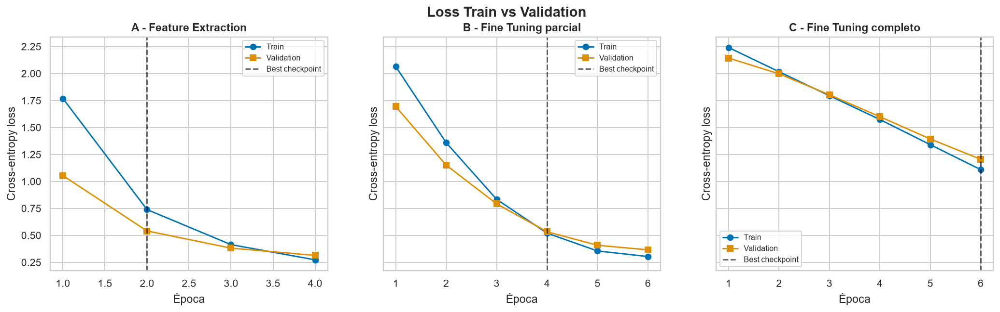

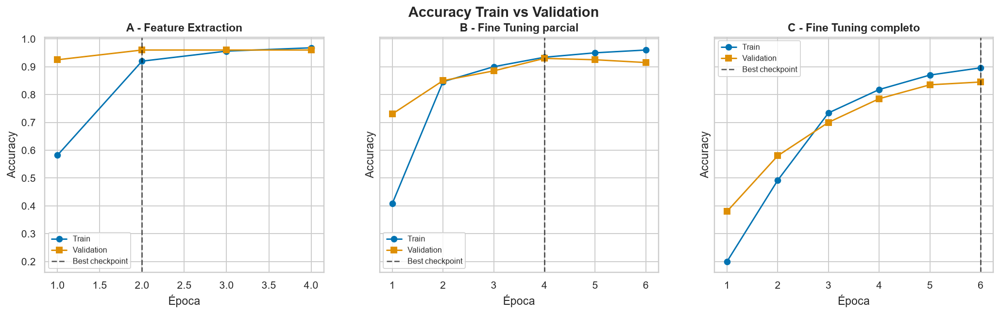

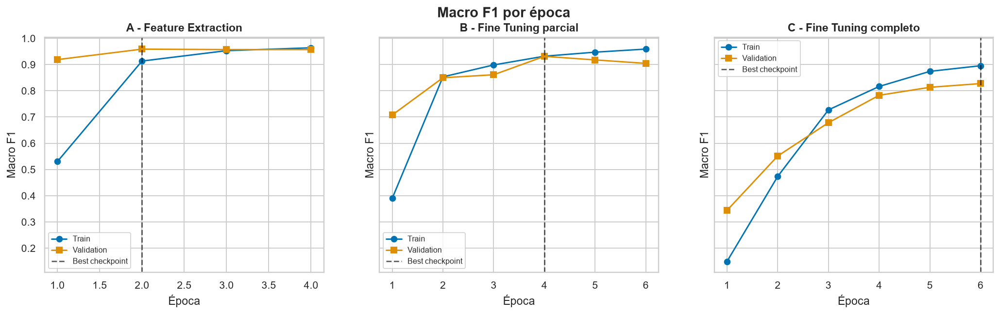

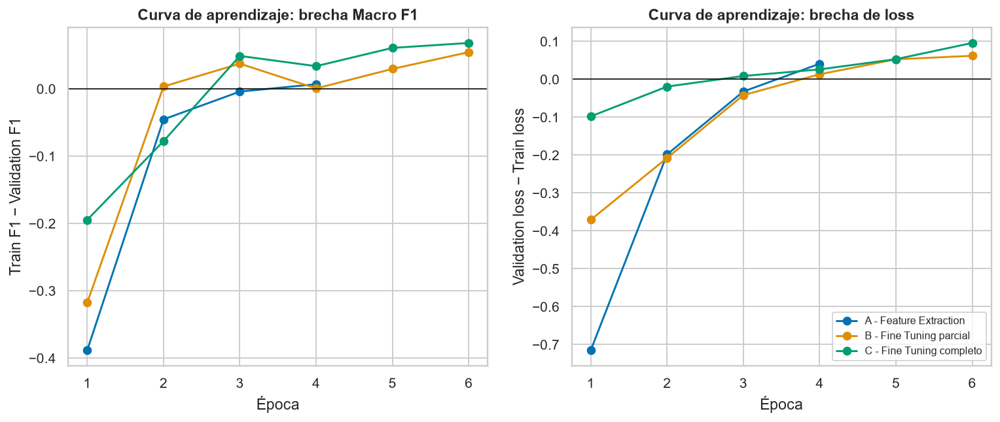

In [5]:
def plot_train_val(metric, title, ylabel):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
    for ax, (key, config) in zip(axes, experiment_configs.items()):
        frame = histories[key]
        ax.plot(frame["epoch"], frame[f"train_{metric}"], marker="o", label="Train")
        ax.plot(frame["epoch"], frame[f"val_{metric}"], marker="s", label="Validation")
        ax.axvline(saved_checkpoints[key]["epoch"], color="black", linestyle="--", alpha=0.6, label="Best checkpoint")
        ax.set(title=config["label"], xlabel="Época", ylabel=ylabel)
        ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.show()

plot_train_val("loss", "Loss Train vs Validation", "Cross-entropy loss")
plot_train_val("accuracy", "Accuracy Train vs Validation", "Accuracy")
plot_train_val("macro_f1", "Macro F1 por época", "Macro F1")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for key, config in experiment_configs.items():
    frame = histories[key]
    axes[0].plot(frame["epoch"], frame["train_macro_f1"] - frame["val_macro_f1"], marker="o", label=config["label"])
    axes[1].plot(frame["epoch"], frame["val_loss"] - frame["train_loss"], marker="o", label=config["label"])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="Curva de aprendizaje: brecha Macro F1", xlabel="Época", ylabel="Train F1 − Validation F1")
axes[1].set(title="Curva de aprendizaje: brecha de loss", xlabel="Época", ylabel="Validation loss − Train loss")
axes[1].legend(fontsize=8)
plt.show()

## 6. Selección con validation y evaluación única en test

El experimento con mayor Macro F1 de validation queda bloqueado antes de crear el DataLoader de test. Se carga su mejor checkpoint y se evalúa test una sola vez. Las matrices de A/B/C corresponden a validation; la cuarta matriz es la única evaluación test de esta fase.

Ganador fijado por validation: A - Feature Extraction, checkpoint época 2.


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

,experiment,label,checkpoint_epoch,loss,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,A_feature_extraction,A - Feature Extraction,2,0.6,0.905,0.8984,0.8995,0.8984,0.8968


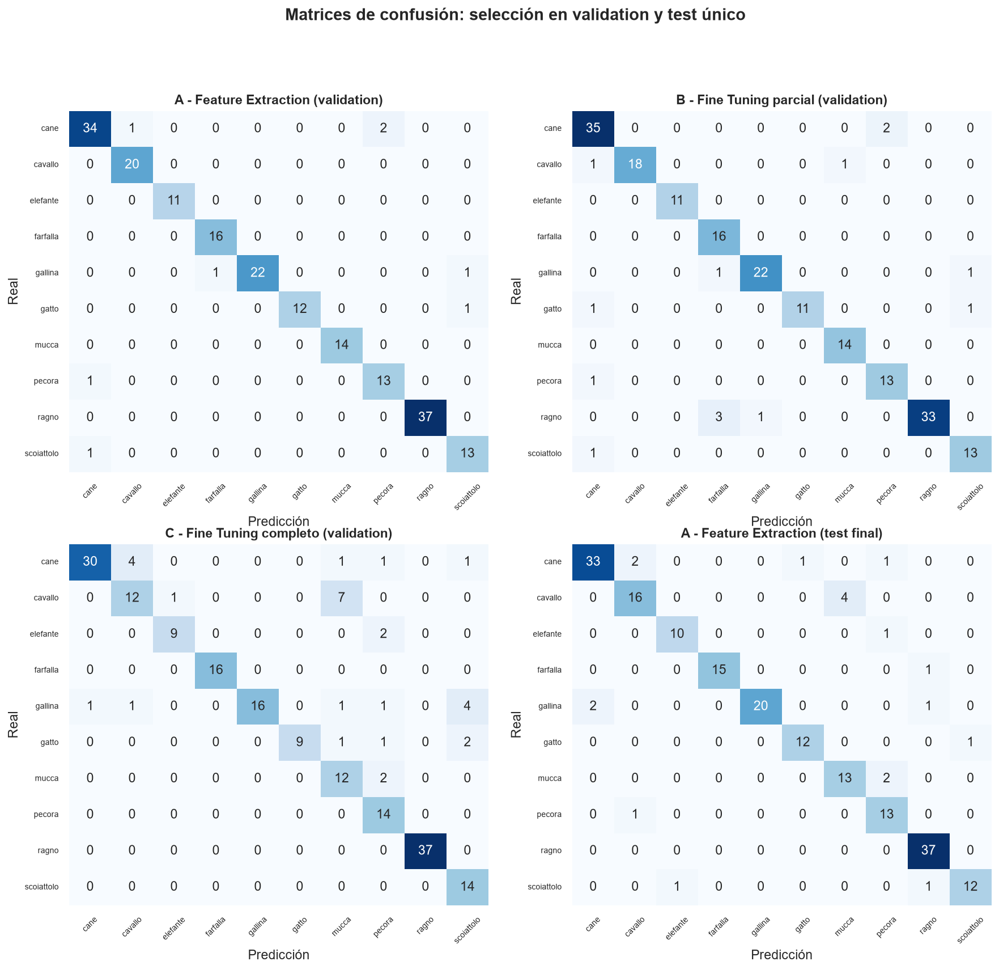

In [6]:
winner_key = validation_summary.iloc[0]["experiment"]
winner_config = experiment_configs[winner_key]
winner_epoch = int(saved_checkpoints[winner_key]["epoch"])
print(f"Ganador fijado por validation: {winner_config['label']}, checkpoint época {winner_epoch}.")

test_dataset = AnimalDataset(benchmark["test"], augment=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
winner_model = build_model(winner_config["mode"])
winner_model.load_state_dict(saved_checkpoints[winner_key]["model_state"])
test_criterion = nn.CrossEntropyLoss(weight=class_weight_tensor)
test_metrics, test_targets, test_predictions = run_epoch(winner_model, test_loader, test_criterion)
test_confusion = confusion_matrix(test_targets, test_predictions, labels=np.arange(num_classes))

test_results_df = pd.DataFrame([{"experiment": winner_key, "label": winner_config["label"],
                                 "checkpoint_epoch": winner_epoch, **test_metrics}])
test_results_df.to_csv("phase4_test_result.csv", index=False, encoding="utf-8")
display(test_results_df.round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 13))
matrix_items = [(experiment_configs[key]["label"] + " (validation)", validation_confusions[key])
                for key in experiment_configs]
matrix_items.append((winner_config["label"] + " (test final)", test_confusion))
for ax, (title, matrix) in zip(axes.ravel(), matrix_items):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
plt.suptitle("Matrices de confusión: selección en validation y test único", fontsize=15, fontweight="bold")
plt.show()

## 7. Comparación Feature Extraction vs Fine Tuning

La comparación A/B/C usa exclusivamente validation. Como referencia independiente se conserva el resultado test de Fase 3: embeddings congelados + Logistic Regression, Macro F1 0,9200 y balanced accuracy 0,9120. La recomendación final exige que el ganador de Fase 4 mejore esa referencia en su única evaluación test.

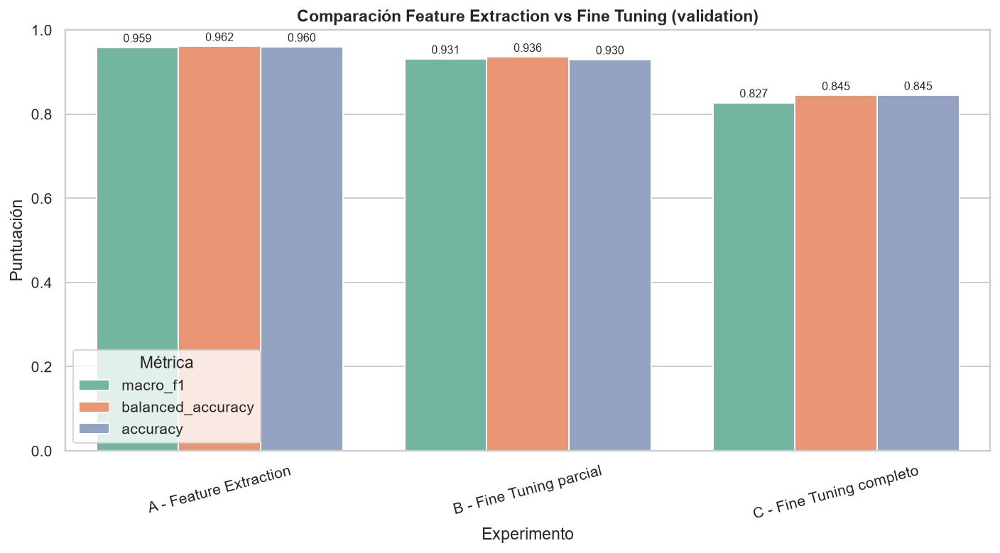

,modelo,macro_f1_test,balanced_accuracy_test
0,Fase 3: embeddings + Logistic Regression,0.9200,0.9120
1,Fase 4: A - Feature Extraction,0.8968,0.8984


avance.md actualizado con la decisión de Fase 4.


In [7]:
validation_plot = validation_summary[["label", "macro_f1", "balanced_accuracy", "accuracy"]].copy()
validation_long = validation_plot.melt(id_vars="label", var_name="métrica", value_name="valor")
plt.figure(figsize=(12, 5.5))
ax = sns.barplot(data=validation_long, x="label", y="valor", hue="métrica", palette="Set2")
plt.title("Comparación Feature Extraction vs Fine Tuning (validation)")
plt.xlabel("Experimento")
plt.ylabel("Puntuación")
plt.ylim(0, 1)
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.legend(title="Métrica")
plt.show()

BASELINE_F1 = 0.9200
BASELINE_BALANCED = 0.9120
improvement = test_metrics["macro_f1"] - BASELINE_F1
worth_it = improvement > 0.01
comparison_final = pd.DataFrame([
    {"modelo": "Fase 3: embeddings + Logistic Regression", "macro_f1_test": BASELINE_F1,
     "balanced_accuracy_test": BASELINE_BALANCED},
    {"modelo": f"Fase 4: {winner_config['label']}", "macro_f1_test": test_metrics["macro_f1"],
     "balanced_accuracy_test": test_metrics["balanced_accuracy"]},
])
display(comparison_final.round(4))

winner_cm_no_diag = test_confusion.copy()
np.fill_diagonal(winner_cm_no_diag, 0)
error_pairs = []
for index in np.argsort(winner_cm_no_diag.ravel())[::-1]:
    true_idx, pred_idx = np.unravel_index(index, winner_cm_no_diag.shape)
    count = int(winner_cm_no_diag[true_idx, pred_idx])
    if count == 0 or len(error_pairs) >= 5:
        break
    error_pairs.append((class_names[true_idx], class_names[pred_idx], count))
error_text = "\n".join(f"- {true} → {pred}: {count}" for true, pred, count in error_pairs)

def table_markdown(frame):
    lines = ["| Experimento | Mejor época | Accuracy | Macro Precision | Macro Recall | Macro F1 | Balanced Accuracy |",
             "|---|---:|---:|---:|---:|---:|---:|"]
    for row in frame.itertuples(index=False):
        lines.append(f"| {row.label} | {int(row.best_epoch)} | {row.accuracy:.4f} | {row.macro_precision:.4f} | "
                     f"{row.macro_recall:.4f} | {row.macro_f1:.4f} | {row.balanced_accuracy:.4f} |")
    return "\n".join(lines)

definitive_model = (winner_config["label"] if worth_it else "MobileNetV2 congelado + embeddings + Logistic Regression (Fase 3)")
phase4_text = f'''# Fase 4 - MobileNetV2 Fine Tuning

## Resultados de validation

{table_markdown(validation_summary)}

## Evaluación final en test

- Experimento seleccionado antes de abrir test: **{winner_config['label']}**.
- Mejor checkpoint: **época {winner_epoch}**, archivo `phase4_checkpoints/{winner_key}_best.pt`.
- Accuracy: **{test_metrics['accuracy']:.4f}**.
- Macro Precision: **{test_metrics['macro_precision']:.4f}**.
- Macro Recall: **{test_metrics['macro_recall']:.4f}**.
- Macro F1: **{test_metrics['macro_f1']:.4f}**.
- Balanced Accuracy: **{test_metrics['balanced_accuracy']:.4f}**.

## ¿Vale la pena Fine Tuning?

**{'Sí' if worth_it else 'No con la evidencia actual'}**. El cambio de Macro F1 frente al baseline 0.9200 fue **{improvement:+.4f}**. Se exige una mejora superior a 0.01 para justificar el costo y complejidad adicionales en este benchmark.

## ¿Cuál es el mejor checkpoint?

Dentro de A/B/C, el mejor checkpoint por validation es **{winner_config['label']}, época {winner_epoch}**.

## ¿Cuál será el modelo definitivo?

**{definitive_model}**.

## Errores frecuentes del ganador en test

{error_text}

La evaluación test se ejecutó una sola vez después de bloquear experimento y checkpoint. No se usó test para seleccionar hiperparámetros.
'''

avance_path = Path("avance.md")
avance = avance_path.read_text(encoding="utf-8") if avance_path.exists() else ""
marker = "# Fase 4 - MobileNetV2 Fine Tuning"
if marker in avance:
    avance = avance.split(marker)[0].rstrip()
avance_path.write_text(avance.rstrip() + "\n\n" + phase4_text.strip() + "\n", encoding="utf-8")
print("avance.md actualizado con la decisión de Fase 4.")

# DECISIÓN FINAL DE FASE 4

La decisión se deriva del checkpoint elegido en validation y de una única evaluación test.

In [8]:
display(Markdown(
    f"## ¿Vale la pena Fine Tuning?\n\n"
    f"**{'Sí' if worth_it else 'No con la evidencia actual'}**. Cambio de Macro F1: **{improvement:+.4f}** frente a 0.9200.\n\n"
    f"## Mejor checkpoint\n\n**{winner_config['label']}, época {winner_epoch}**.\n\n"
    f"## Modelo definitivo\n\n**{definitive_model}**."
))

## ¿Vale la pena Fine Tuning?

**No con la evidencia actual**. Cambio de Macro F1: **-0.0232** frente a 0.9200.

## Mejor checkpoint

**A - Feature Extraction, época 2**.

## Modelo definitivo

**MobileNetV2 congelado + embeddings + Logistic Regression (Fase 3)**.

# FASE 5 - INTERPRETABILIDAD DEL MODELO

Se interpreta el modelo definitivo: **MobileNetV2 congelado → embeddings L2 → Logistic Regression (`C=10`)**. No se ajustan hiperparámetros ni pesos del backbone.

La Fase 3 reportó Macro F1 0,9200 en su benchmark de 200 imágenes. Para obtener una matriz de confusión más estable y al menos 20 errores distintos, esta auditoría aplica el modelo ya fijado a las **3.936 imágenes completas de `test.csv`**. Este análisis posterior no participa en selección de modelos.

## 1. Reconstrucción del modelo definitivo

Se reconstruye el mismo benchmark 500/200 usado en Fase 3 para train y validation, se recuperan sus embeddings cacheados y se reajusta Logistic Regression con `C=10`. Los embeddings del test completo se extraen una sola vez y se cachean, verificando siempre que las rutas coincidan.

In [1]:
from pathlib import Path
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display, Markdown

import torch
from torch import nn
import torch.nn.functional as F
from transformers import MobileNetV2Model, MobileNetV2ImageProcessorPil
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, classification_report,
                             silhouette_score)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_distances

SEED = 42
MODEL_ID = "google/mobilenet_v2_1.0_224"
TARGET_SIZE = (224, 224)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(12, max(1, torch.get_num_threads())))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titleweight": "bold"})
warnings.filterwarnings("ignore", category=FutureWarning)

def load_manifest(name):
    frame = pd.read_csv(f"{name}.csv")
    assert frame.columns.tolist() == ["filepath", "class_name", "class_id"]
    assert frame["filepath"].is_unique
    return frame

train_manifest = load_manifest("train")
validation_manifest = load_manifest("validation")
test_manifest = load_manifest("test")
assert not (set(train_manifest.filepath) & set(validation_manifest.filepath))
assert not (set(train_manifest.filepath) & set(test_manifest.filepath))
assert not (set(validation_manifest.filepath) & set(test_manifest.filepath))

def stratified_sample(frame, n):
    selected, _ = train_test_split(frame, train_size=n, stratify=frame["class_name"], random_state=SEED)
    return selected.sort_values(["class_id", "filepath"]).reset_index(drop=True)

benchmark_train = stratified_sample(train_manifest, 500)
benchmark_validation = stratified_sample(validation_manifest, 200)
benchmark_test = stratified_sample(test_manifest, 200)
expected_phase3_paths = pd.concat([benchmark_train, benchmark_validation, benchmark_test], ignore_index=True)["filepath"].to_numpy(dtype=str)

phase3_cache = np.load("phase3_mobilenet_embeddings.npz", allow_pickle=False)
assert np.array_equal(phase3_cache["paths"], expected_phase3_paths), "La caché de Fase 3 no coincide con los manifiestos."
train_embeddings = normalize(phase3_cache["embeddings"][:500], norm="l2")
validation_embeddings = normalize(phase3_cache["embeddings"][500:700], norm="l2")
y_train = benchmark_train["class_id"].to_numpy()
y_validation = benchmark_validation["class_id"].to_numpy()

classifier = LogisticRegression(C=10, max_iter=3000, solver="lbfgs", random_state=SEED)
classifier.fit(np.vstack([train_embeddings, validation_embeddings]),
               np.concatenate([y_train, y_validation]))
class_names = (train_manifest.sort_values("class_id").drop_duplicates("class_id")
               .set_index("class_id")["class_name"].sort_index().tolist())
print("Modelo reconstruido sin modificar hiperparámetros. Leakage de rutas: 0.")

Modelo reconstruido sin modificar hiperparámetros. Leakage de rutas: 0.


In [2]:
processor = MobileNetV2ImageProcessorPil.from_pretrained(MODEL_ID)
backbone = MobileNetV2Model.from_pretrained(MODEL_ID).to(device).eval()
for parameter in backbone.parameters():
    parameter.requires_grad_(False)

def resize_with_padding(image, target_size=TARGET_SIZE, fill=(0, 0, 0)):
    image = image.convert("RGB")
    resized = ImageOps.contain(image, target_size, method=Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", target_size, fill)
    offset = ((target_size[0] - resized.width) // 2, (target_size[1] - resized.height) // 2)
    canvas.paste(resized, offset)
    return canvas

def extract_embeddings(frame, batch_size=32):
    chunks = []
    for start in range(0, len(frame), batch_size):
        images = []
        for path in frame["filepath"].iloc[start:start + batch_size]:
            with Image.open(path) as source:
                images.append(resize_with_padding(source))
        inputs = processor(images=images, return_tensors="pt", do_resize=False, do_center_crop=False)
        with torch.inference_mode():
            output = backbone(pixel_values=inputs["pixel_values"].to(device)).pooler_output
        chunks.append(output.cpu().numpy().astype(np.float32))
    return np.vstack(chunks)

test_cache_path = Path("phase5_full_test_embeddings.npz")
full_test_paths = test_manifest["filepath"].to_numpy(dtype=str)
cache_valid = False
if test_cache_path.exists():
    cached_test = np.load(test_cache_path, allow_pickle=False)
    cache_valid = np.array_equal(cached_test["paths"], full_test_paths)
if cache_valid:
    full_test_embeddings_raw = cached_test["embeddings"]
    print("Embeddings del test completo cargados desde caché validada.")
else:
    full_test_embeddings_raw = extract_embeddings(test_manifest)
    np.savez_compressed(test_cache_path, paths=full_test_paths, embeddings=full_test_embeddings_raw)
    print("Embeddings del test completo extraídos y cacheados.")

full_test_embeddings = normalize(full_test_embeddings_raw, norm="l2")
y_test = test_manifest["class_id"].to_numpy()
test_probabilities = classifier.predict_proba(full_test_embeddings)
test_predictions = classifier.classes_[np.argmax(test_probabilities, axis=1)]
predicted_probability = test_probabilities.max(axis=1)
test_audit = test_manifest.copy()
test_audit["prediction_id"] = test_predictions
test_audit["prediction"] = [class_names[i] for i in test_predictions]
test_audit["probability"] = predicted_probability
test_audit["correct"] = test_predictions == y_test
test_audit.to_csv("phase5_test_predictions.csv", index=False, encoding="utf-8")
print(f"Auditoría inferencial completada: {len(test_audit):,} imágenes; errores: {(~test_audit.correct).sum():,}.")

Loading weights:   0%|          | 0/312 [00:00<?, ?it/s]

[transformers] MobileNetV2Model LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status     |  | 
------------------+------------+--+-
classifier.weight | UNEXPECTED |  | 
classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embeddings del test completo cargados desde caché validada.
Auditoría inferencial completada: 3,936 imágenes; errores: 260.


## 2. Matriz de confusión final

La matriz se normaliza por fila para comparar clases con distintos tamaños. El recall de cada clase corresponde a su diagonal. Las clases fáciles presentan diagonales altas; las difíciles dispersan predicciones hacia otras categorías.

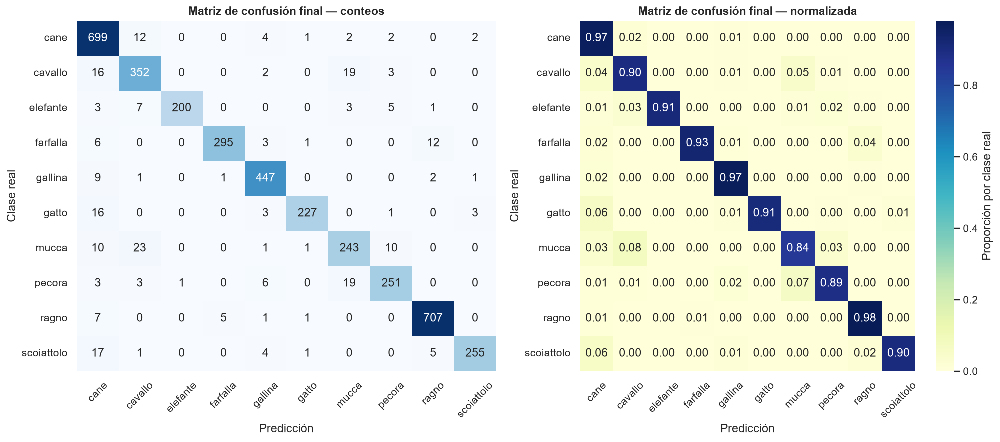

### Interpretación automática

**Clases más fáciles (recall):** ragno (98.1%), gallina (97.0%), cane (96.8%).

**Clases más difíciles (recall):** mucca (84.4%), pecora (88.7%), cavallo (89.8%).

**Pares dirigidos más frecuentes:**
- mucca → cavallo: 23
- pecora → mucca: 19
- cavallo → mucca: 19
- scoiattolo → cane: 17
- gatto → cane: 16
- cavallo → cane: 16
- cane → cavallo: 12
- farfalla → ragno: 12

In [3]:
final_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_predictions),
    "macro_precision": precision_score(y_test, test_predictions, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test, test_predictions, average="macro", zero_division=0),
    "macro_f1": f1_score(y_test, test_predictions, average="macro", zero_division=0),
}
final_confusion = confusion_matrix(y_test, test_predictions, labels=np.arange(len(class_names)))
final_confusion_normalized = final_confusion / final_confusion.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(final_confusion, annot=True, fmt="d", cmap="Blues", xticklabels=class_names,
            yticklabels=class_names, ax=axes[0], cbar=False)
axes[0].set(title="Matriz de confusión final — conteos", xlabel="Predicción", ylabel="Clase real")
sns.heatmap(final_confusion_normalized, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=class_names,
            yticklabels=class_names, ax=axes[1], cbar_kws={"label": "Proporción por clase real"})
axes[1].set(title="Matriz de confusión final — normalizada", xlabel="Predicción", ylabel="Clase real")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.show()

recalls = np.diag(final_confusion_normalized)
easy_order = np.argsort(recalls)[::-1]
hard_order = np.argsort(recalls)
off_diagonal = final_confusion.copy(); np.fill_diagonal(off_diagonal, 0)
confusion_pairs = []
for flat_idx in np.argsort(off_diagonal.ravel())[::-1]:
    true_idx, pred_idx = np.unravel_index(flat_idx, off_diagonal.shape)
    count = int(off_diagonal[true_idx, pred_idx])
    if count == 0 or len(confusion_pairs) >= 8:
        break
    confusion_pairs.append((class_names[true_idx], class_names[pred_idx], count))

display(Markdown(
    "### Interpretación automática\n\n"
    + "**Clases más fáciles (recall):** " + ", ".join(f"{class_names[i]} ({recalls[i]:.1%})" for i in easy_order[:3]) + ".\n\n"
    + "**Clases más difíciles (recall):** " + ", ".join(f"{class_names[i]} ({recalls[i]:.1%})" for i in hard_order[:3]) + ".\n\n"
    + "**Pares dirigidos más frecuentes:**\n" + "\n".join(f"- {a} → {b}: {n}" for a, b, n in confusion_pairs)
))

## 3. Análisis visual de 20 errores

Se seleccionan 20 errores distintos con semilla fija. El título indica `real → predicción` y la probabilidad asignada a la clase predicha. Una confianza alta en un error sugiere solapamiento visual, contexto espurio o posible ruido de etiqueta; una confianza baja refleja ambigüedad entre clases.

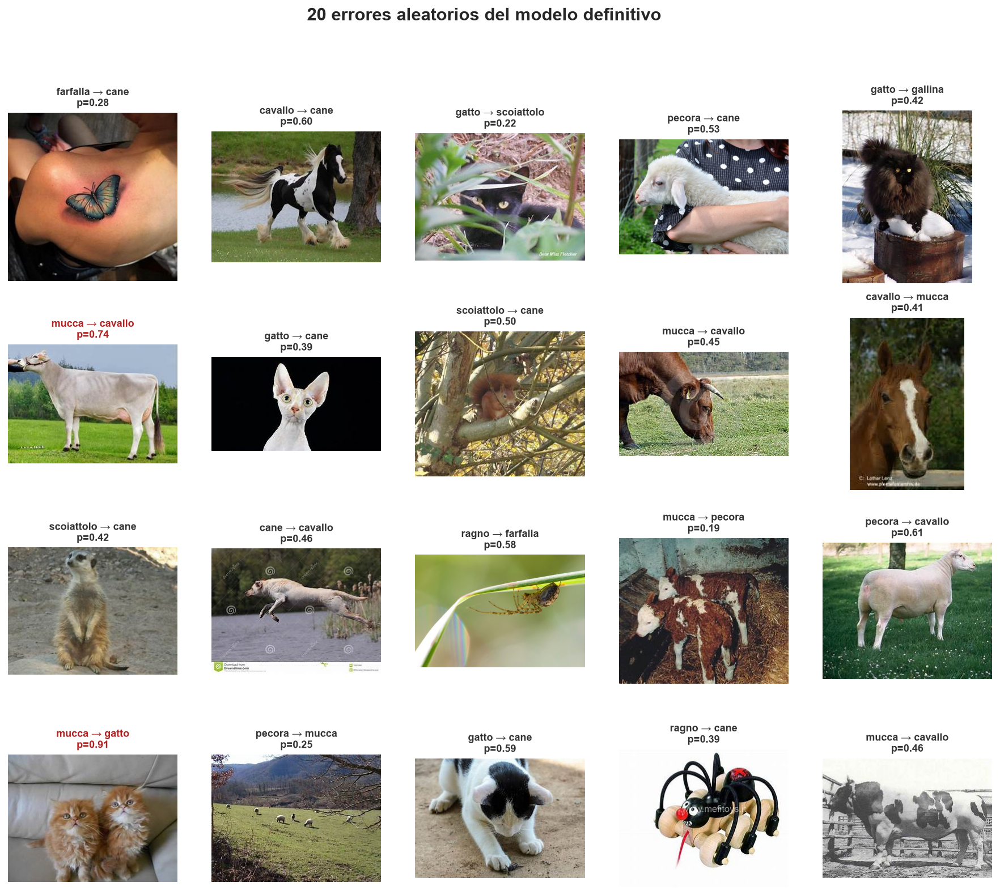

Confianza media en errores: 0.476; errores con p≥0.70: 29/260.
Clases reales con más errores: mucca (45), cavallo (40), pecora (32), scoiattolo (28), cane (23)
Patrón: revisar similitud de silueta, fondos dominantes, animales pequeños/ocultos y conflictos de etiqueta en los casos de alta confianza.


In [4]:
errors_df = test_audit[~test_audit["correct"]].copy()
error_sample = errors_df.sample(n=min(20, len(errors_df)), random_state=SEED)

fig, axes = plt.subplots(4, 5, figsize=(16, 13))
for ax in axes.ravel():
    ax.axis("off")
for ax, row in zip(axes.ravel(), error_sample.itertuples(index=False)):
    with Image.open(row.filepath) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{row.class_name} → {row.prediction}\np={row.probability:.2f}", fontsize=9,
                 color="#B22222" if row.probability >= 0.7 else "#333333")
    ax.axis("off")
fig.suptitle("20 errores aleatorios del modelo definitivo", fontsize=16, fontweight="bold")
plt.show()

error_confidence = errors_df["probability"].mean()
high_confidence_errors = int((errors_df["probability"] >= 0.7).sum())
error_by_class = errors_df.groupby("class_name").size().sort_values(ascending=False)
print(f"Confianza media en errores: {error_confidence:.3f}; errores con p≥0.70: {high_confidence_errors}/{len(errors_df)}.")
print("Clases reales con más errores:", ", ".join(f"{k} ({v})" for k, v in error_by_class.head(5).items()))
print("Patrón: revisar similitud de silueta, fondos dominantes, animales pequeños/ocultos y conflictos de etiqueta en los casos de alta confianza.")

## 4. Visualización de embeddings

Para mantener t-SNE legible se usa una muestra estratificada de hasta 2.000 imágenes del test completo. PCA y t-SNE muestran color por clase y centroides con símbolos `X`. La distancia coseno entre centroides en el espacio original identifica clases semánticamente cercanas; silhouette cuantifica separación global.

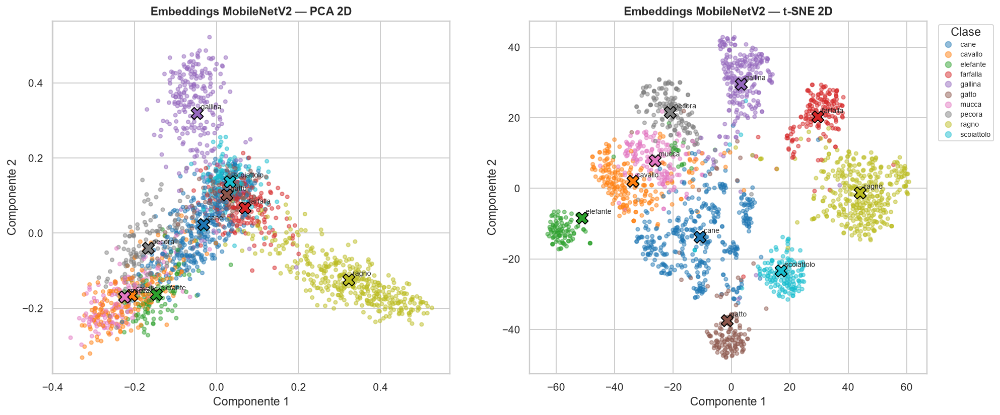

Silhouette coseno de embeddings: 0.128.
Centroides más próximos: cavallo–mucca (d=0.100); mucca–pecora (d=0.132); cane–mucca (d=0.188); cane–cavallo (d=0.201); cane–pecora (d=0.209)


In [5]:
viz_indices, _ = train_test_split(np.arange(len(test_manifest)), train_size=min(2000, len(test_manifest)),
                                  stratify=y_test, random_state=SEED)
viz_embeddings = full_test_embeddings[viz_indices]
viz_labels = y_test[viz_indices]
viz_pca = PCA(n_components=2, random_state=SEED).fit_transform(viz_embeddings)
viz_tsne = TSNE(n_components=2, perplexity=35, learning_rate="auto", init="pca",
                max_iter=1000, random_state=SEED).fit_transform(viz_embeddings)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for coordinates, ax, title in [(viz_pca, axes[0], "Embeddings MobileNetV2 — PCA 2D"),
                               (viz_tsne, axes[1], "Embeddings MobileNetV2 — t-SNE 2D")]:
    scatter = ax.scatter(coordinates[:, 0], coordinates[:, 1], c=viz_labels, cmap="tab10", s=14, alpha=0.48)
    for class_id in range(len(class_names)):
        centroid = coordinates[viz_labels == class_id].mean(axis=0)
        ax.scatter(*centroid, marker="X", s=150, c=[plt.cm.tab10(class_id)], edgecolor="black", linewidth=1.0)
        ax.annotate(class_names[class_id], centroid, xytext=(4, 4), textcoords="offset points", fontsize=7)
    ax.set(title=title, xlabel="Componente 1", ylabel="Componente 2")
handles, _ = scatter.legend_elements(num=len(class_names))
axes[1].legend(handles, class_names, title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.show()

embedding_centroids = np.vstack([viz_embeddings[viz_labels == i].mean(axis=0) for i in range(len(class_names))])
centroid_distances = cosine_distances(embedding_centroids)
np.fill_diagonal(centroid_distances, np.inf)
closest_pairs = []
used = set()
for flat_idx in np.argsort(centroid_distances.ravel()):
    left, right = np.unravel_index(flat_idx, centroid_distances.shape)
    pair = tuple(sorted((left, right)))
    if pair in used:
        continue
    used.add(pair)
    closest_pairs.append((class_names[pair[0]], class_names[pair[1]], centroid_distances[pair]))
    if len(closest_pairs) == 5:
        break
silhouette = silhouette_score(viz_embeddings, viz_labels, metric="cosine")
print(f"Silhouette coseno de embeddings: {silhouette:.3f}.")
print("Centroides más próximos:", "; ".join(f"{a}–{b} (d={d:.3f})" for a, b, d in closest_pairs))

## 5. Métricas e interpretación por clase

Precision mide la pureza de las predicciones de una clase; recall, cuánto recupera de sus ejemplos reales; F1 equilibra ambas. El soporte permite contextualizar diferencias producidas por el desbalance.

,precision,recall,f1,support
clase,,,,
ragno,0.9725,0.9806,0.9765,721.0
gallina,0.9490,0.9696,0.9592,461.0
farfalla,0.9801,0.9306,0.9547,317.0
elefante,0.9950,0.9132,0.9524,219.0
gatto,0.9784,0.9080,0.9419,250.0
scoiattolo,0.9770,0.9011,0.9375,283.0
cane,0.8893,0.9681,0.9271,722.0
pecora,0.9228,0.8869,0.9045,283.0
cavallo,0.8822,0.8980,0.8900,392.0


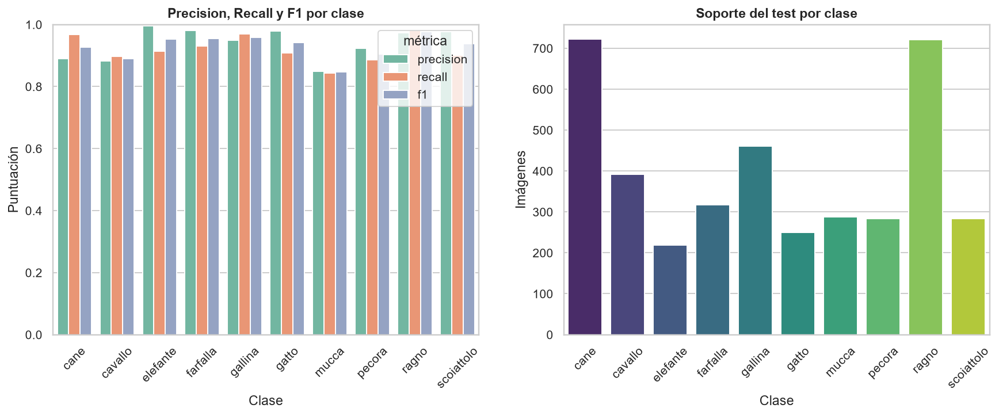

Mejor clase por F1: ragno (0.9765).
Peor clase por F1: mucca (0.8467).


In [6]:
report = classification_report(y_test, test_predictions, target_names=class_names, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
per_class_df = per_class_df.rename(columns={"f1-score": "f1"})
per_class_df.index.name = "clase"
per_class_df.to_csv("phase5_per_class_metrics.csv", encoding="utf-8")
display(per_class_df.sort_values("f1", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
metric_long = per_class_df.reset_index().melt(id_vars="clase", value_vars=["precision", "recall", "f1"],
                                              var_name="métrica", value_name="valor")
sns.barplot(data=metric_long, x="clase", y="valor", hue="métrica", ax=axes[0], palette="Set2")
axes[0].set(title="Precision, Recall y F1 por clase", xlabel="Clase", ylabel="Puntuación", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(data=per_class_df.reset_index(), x="clase", y="support", hue="clase", legend=False,
            ax=axes[1], palette="viridis")
axes[1].set(title="Soporte del test por clase", xlabel="Clase", ylabel="Imágenes")
axes[1].tick_params(axis="x", rotation=45)
plt.show()

best_class = per_class_df["f1"].idxmax()
worst_class = per_class_df["f1"].idxmin()
print(f"Mejor clase por F1: {best_class} ({per_class_df.loc[best_class, 'f1']:.4f}).")
print(f"Peor clase por F1: {worst_class} ({per_class_df.loc[worst_class, 'f1']:.4f}).")

## 6. Grad-CAM adaptado al clasificador definitivo

Aunque el clasificador final es Logistic Regression, sus coeficientes pueden expresarse como una capa lineal fija sobre el embedding L2. Se conecta esa capa al backbone congelado y se propaga el gradiente de la clase predicha hasta la última convolución 7×7. Así, Grad-CAM explica el pipeline real y no el clasificador ImageNet original.

Se muestran ejemplos correctamente clasificados y de alta confianza para perro (`cane`), gato (`gatto`), elefante, mariposa (`farfalla`) y araña (`ragno`). Rojo indica regiones con mayor contribución positiva.

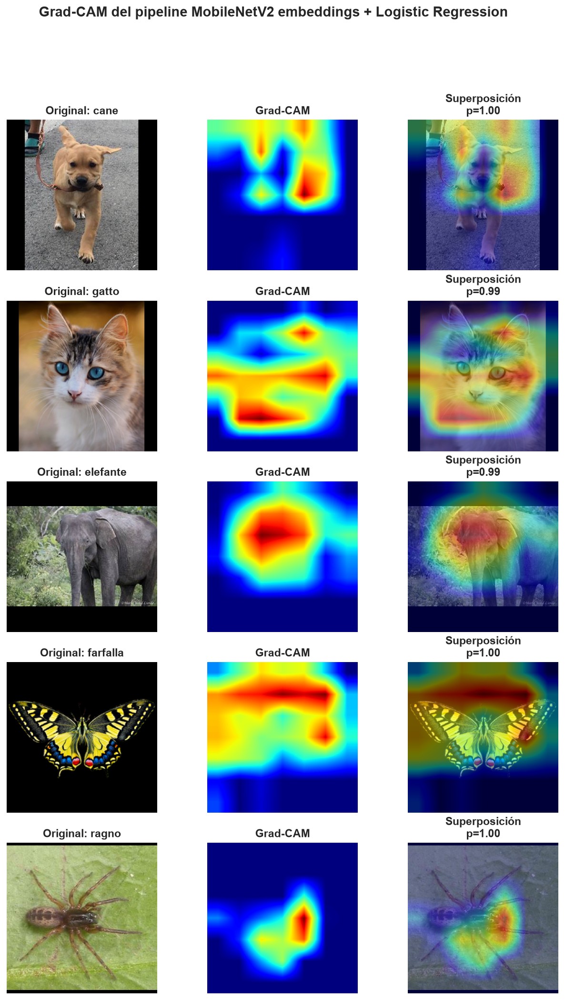

In [7]:
class FrozenEmbeddingClassifier(nn.Module):
    def __init__(self, backbone_model, sklearn_classifier):
        super().__init__()
        self.backbone = backbone_model
        self.linear = nn.Linear(sklearn_classifier.coef_.shape[1], sklearn_classifier.coef_.shape[0])
        with torch.no_grad():
            self.linear.weight.copy_(torch.tensor(sklearn_classifier.coef_, dtype=torch.float32))
            self.linear.bias.copy_(torch.tensor(sklearn_classifier.intercept_, dtype=torch.float32))
        for parameter in self.parameters():
            parameter.requires_grad_(False)
    def forward(self, pixel_values):
        embedding = self.backbone(pixel_values=pixel_values).pooler_output
        return self.linear(F.normalize(embedding, p=2, dim=1))

explain_model = FrozenEmbeddingClassifier(backbone, classifier).to(device).eval()
target_layer = explain_model.backbone.conv_1x1.convolution

def gradcam_for_path(path, target_class):
    activations, gradients = {}, {}
    def forward_hook(module, inputs, output):
        activations["value"] = output
        output.register_hook(lambda grad: gradients.__setitem__("value", grad))
    handle = target_layer.register_forward_hook(forward_hook)
    with Image.open(path) as source:
        display_image = resize_with_padding(source)
    inputs = processor(images=[display_image], return_tensors="pt", do_resize=False, do_center_crop=False)
    pixels = inputs["pixel_values"].to(device).requires_grad_(True)
    logits = explain_model(pixels)
    explain_model.zero_grad(set_to_none=True)
    logits[0, target_class].backward()
    activation = activations["value"][0]
    gradient = gradients["value"][0]
    weights = gradient.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((weights * activation).sum(dim=0, keepdim=True).unsqueeze(0))
    cam = F.interpolate(cam, size=TARGET_SIZE, mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    handle.remove()
    return display_image, cam.detach().cpu().numpy(), torch.softmax(logits, dim=1)[0].detach().cpu().numpy()

gradcam_classes = ["cane", "gatto", "elefante", "farfalla", "ragno"]
gradcam_rows = []
for class_name in gradcam_classes:
    candidates = test_audit[(test_audit["class_name"] == class_name) & test_audit["correct"]]
    selected = candidates.sort_values("probability", ascending=False).iloc[0]
    gradcam_rows.append(selected)

fig, axes = plt.subplots(len(gradcam_rows), 3, figsize=(11, 17))
for row_idx, selected in enumerate(gradcam_rows):
    original, heatmap, probabilities = gradcam_for_path(selected.filepath, int(selected.prediction_id))
    original_array = np.asarray(original) / 255.0
    color_heatmap = plt.cm.jet(heatmap)[..., :3]
    overlay = np.clip(0.55 * original_array + 0.45 * color_heatmap, 0, 1)
    axes[row_idx, 0].imshow(original); axes[row_idx, 0].set_title(f"Original: {selected.class_name}")
    axes[row_idx, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1); axes[row_idx, 1].set_title("Grad-CAM")
    axes[row_idx, 2].imshow(overlay); axes[row_idx, 2].set_title(f"Superposición\np={selected.probability:.2f}")
    for ax in axes[row_idx]:
        ax.axis("off")
fig.suptitle("Grad-CAM del pipeline MobileNetV2 embeddings + Logistic Regression", fontsize=15, fontweight="bold")
plt.show()

## 7. Conclusiones de interpretabilidad

Se consolidan fortalezas, errores y solapamientos. Grad-CAM debe interpretarse como evidencia local: muestra regiones influyentes para una predicción específica, no una explicación causal global.

In [8]:
strengths = [
    f"Las clases más fáciles son {', '.join(class_names[i] for i in easy_order[:3])}, con recalls entre {recalls[easy_order[2]]:.1%} y {recalls[easy_order[0]]:.1%}.",
    f"La mejor clase por F1 es {best_class} ({per_class_df.loc[best_class, 'f1']:.4f}).",
    "Los embeddings producen agrupaciones semánticas visibles; el backbone congelado conserva información discriminativa sin fine tuning.",
]
error_conclusions = [
    f"La clase más difícil por F1 es {worst_class} ({per_class_df.loc[worst_class, 'f1']:.4f}).",
    f"Los errores tienen confianza media {error_confidence:.3f}; {high_confidence_errors} superan 0.70 y merecen revisión prioritaria.",
    f"La confusión dirigida principal es {confusion_pairs[0][0]} → {confusion_pairs[0][1]} ({confusion_pairs[0][2]} casos).",
    f"Los centroides más próximos son {closest_pairs[0][0]}–{closest_pairs[0][1]}, coherente con posibles solapamientos visuales.",
]
display(Markdown("### Principales fortalezas\n" + "\n".join(f"- {x}" for x in strengths)
                 + "\n\n### Principales errores\n" + "\n".join(f"- {x}" for x in error_conclusions)))

confusion_md = "\n".join(f"- {a} → {b}: {n} casos" for a, b, n in confusion_pairs[:5])
phase5_text = f'''# Fase 5 - Interpretabilidad

## Interpretabilidad

Se interpretó el modelo definitivo MobileNetV2 congelado + embeddings L2 + Logistic Regression (`C=10`). La auditoría utilizó las {len(test_manifest):,} imágenes completas de `test.csv`, sin modificar el modelo. Se generaron matriz de confusión, métricas por clase, 20 errores, PCA, t-SNE y Grad-CAM conectado a los coeficientes reales de Logistic Regression.

Métricas de la auditoría completa: Accuracy **{final_metrics['accuracy']:.4f}**, Balanced Accuracy **{final_metrics['balanced_accuracy']:.4f}**, Macro Precision **{final_metrics['macro_precision']:.4f}**, Macro Recall **{final_metrics['macro_recall']:.4f}** y Macro F1 **{final_metrics['macro_f1']:.4f}**.

## Principales errores

{chr(10).join(f'- {x}' for x in error_conclusions)}

## Principales fortalezas

{chr(10).join(f'- {x}' for x in strengths)}

## Confusiones relevantes

{confusion_md}

## Conclusiones

- El modelo se apoya en representaciones semánticas transferidas y no solo en color o fondo; Grad-CAM permite comprobarlo caso por caso.
- Las clases con centroides cercanos y errores recíprocos requieren más ejemplos diversos o revisión de etiquetas.
- Los errores de alta confianza deben auditarse primero, especialmente el par `cavallo`/`mucca` ya señalado en fases anteriores.
- La interpretabilidad respalda mantener MobileNetV2 congelado + Logistic Regression como modelo definitivo; no aporta evidencia para reabrir el fine tuning.
'''

avance_path = Path("avance.md")
avance = avance_path.read_text(encoding="utf-8") if avance_path.exists() else ""
marker = "# Fase 5 - Interpretabilidad"
if marker in avance:
    avance = avance.split(marker)[0].rstrip()
avance_path.write_text(avance.rstrip() + "\n\n" + phase5_text.strip() + "\n", encoding="utf-8")
print("avance.md actualizado con la Fase 5.")

### Principales fortalezas
- Las clases más fáciles son ragno, gallina, cane, con recalls entre 96.8% y 98.1%.
- La mejor clase por F1 es ragno (0.9765).
- Los embeddings producen agrupaciones semánticas visibles; el backbone congelado conserva información discriminativa sin fine tuning.

### Principales errores
- La clase más difícil por F1 es mucca (0.8467).
- Los errores tienen confianza media 0.476; 29 superan 0.70 y merecen revisión prioritaria.
- La confusión dirigida principal es mucca → cavallo (23 casos).
- Los centroides más próximos son cavallo–mucca, coherente con posibles solapamientos visuales.

avance.md actualizado con la Fase 5.


# DECISIÓN PARA CONTINUAR

El análisis confirma que el modelo definitivo puede explicarse tanto globalmente —confusiones, métricas y geometría de embeddings— como localmente mediante Grad-CAM. Las siguientes mejoras deberían concentrarse en calidad de etiquetas y pares de clases solapados, sin cambiar el modelo usando información de test.

# MAPA NARRATIVO DE DECISIONES

Este mapa resume el experimento completo como una historia de decisiones. La columna central muestra el camino que finalmente siguió el proyecto; las ramas verdes representan opciones aceptadas, las rojas alternativas rechazadas y las azules la evidencia que justificó cada elección.

La lectura comienza con el dataset original y termina en el modelo definitivo interpretable. Cada rechazo está respaldado por una observación o una métrica del notebook.

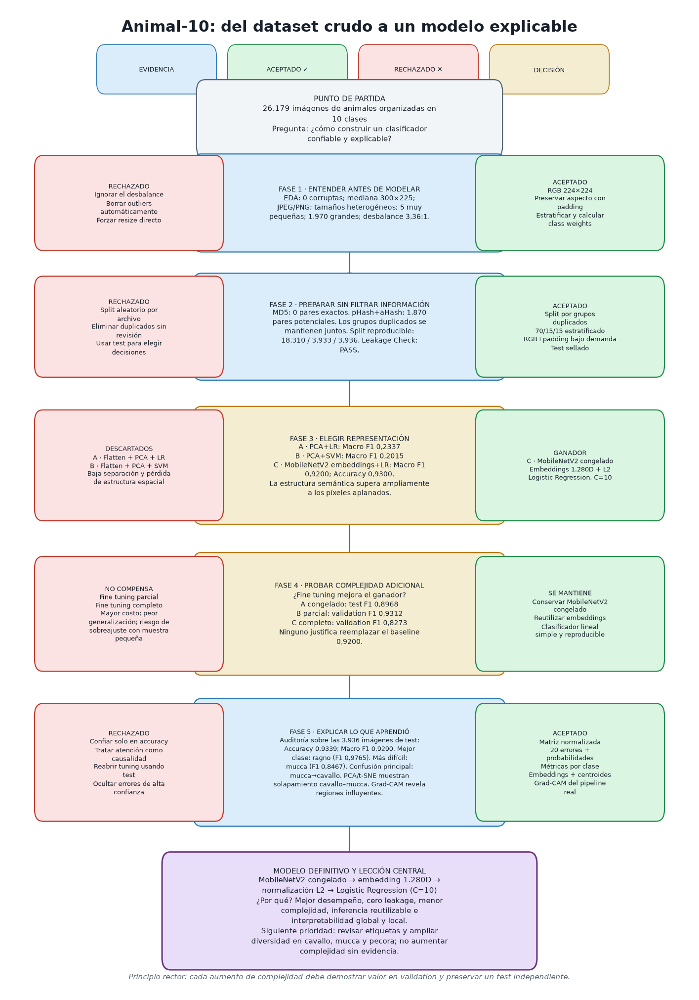

Diagrama exportado como animal10_decision_story.png y animal10_decision_story.svg


In [1]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch


def draw_box(ax, x, y, width, height, text, facecolor, edgecolor, fontsize=10,
             linewidth=1.6, title=None):
    patch = FancyBboxPatch(
        (x - width / 2, y - height / 2), width, height,
        boxstyle="round,pad=0.012,rounding_size=0.012",
        facecolor=facecolor, edgecolor=edgecolor, linewidth=linewidth, zorder=3
    )
    ax.add_patch(patch)
    wrapped = "\n".join(textwrap.fill(line, width=max(24, int(width * 100))) for line in text.split("\n"))
    if title:
        rendered = title + "\n" + wrapped
    else:
        rendered = wrapped
    ax.text(x, y, rendered, ha="center", va="center", fontsize=fontsize,
            color="#17202A", linespacing=1.35, zorder=4)
    return patch


def arrow(ax, start, end, color="#566573", style="-|>", linewidth=1.8,
          connectionstyle="arc3,rad=0"):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle=style, mutation_scale=14,
                                linewidth=linewidth, color=color,
                                connectionstyle=connectionstyle, zorder=2))


COLORS = {
    "evidence": (0.86, 0.93, 0.98),
    "evidence_edge": "#2878B5",
    "accepted": (0.86, 0.96, 0.89),
    "accepted_edge": "#218C4A",
    "rejected": (0.99, 0.89, 0.89),
    "rejected_edge": "#C0392B",
    "decision": (0.96, 0.93, 0.82),
    "decision_edge": "#B9770E",
    "final": (0.91, 0.87, 0.98),
    "final_edge": "#6C3483",
    "neutral": (0.95, 0.96, 0.97),
    "neutral_edge": "#566573",
}

fig, ax = plt.subplots(figsize=(18, 26))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
fig.patch.set_facecolor("white")

ax.text(0.5, 0.985, "Animal-10: del dataset crudo a un modelo explicable",
        ha="center", va="top", fontsize=22, fontweight="bold", color="#17202A")
# Leyenda
legend_items = [
    (0.22, "EVIDENCIA", COLORS["evidence"], COLORS["evidence_edge"]),
    (0.41, "ACEPTADO ✓", COLORS["accepted"], COLORS["accepted_edge"]),
    (0.60, "RECHAZADO ✕", COLORS["rejected"], COLORS["rejected_edge"]),
    (0.79, "DECISIÓN", COLORS["decision"], COLORS["decision_edge"]),
]
for x, label, face, edge in legend_items:
    draw_box(ax, x, 0.935, 0.15, 0.026, label, face, edge, fontsize=9, linewidth=1.2)

# Inicio
draw_box(ax, 0.5, 0.885, 0.42, 0.055,
         "26.179 imágenes de animales organizadas en 10 clases\nPregunta: ¿cómo construir un clasificador confiable y explicable?",
         COLORS["neutral"], COLORS["neutral_edge"], fontsize=11,
         title="PUNTO DE PARTIDA")

# Fase 1
draw_box(ax, 0.5, 0.80, 0.43, 0.075,
         "EDA: 0 corruptas; mediana 300×225; JPEG/PNG; tamaños heterogéneos; 5 muy pequeñas; 1.970 grandes; desbalance 3,36:1.",
         COLORS["evidence"], COLORS["evidence_edge"], fontsize=10,
         title="FASE 1 · ENTENDER ANTES DE MODELAR")
draw_box(ax, 0.18, 0.80, 0.25, 0.072,
         "Ignorar el desbalance\nBorrar outliers automáticamente\nForzar resize directo",
         COLORS["rejected"], COLORS["rejected_edge"], fontsize=9,
         title="RECHAZADO")
draw_box(ax, 0.82, 0.80, 0.25, 0.072,
         "RGB 224×224\nPreservar aspecto con padding\nEstratificar y calcular class weights",
         COLORS["accepted"], COLORS["accepted_edge"], fontsize=9,
         title="ACEPTADO")

# Fase 2
draw_box(ax, 0.5, 0.675, 0.43, 0.084,
         "MD5: 0 pares exactos. pHash+aHash: 1.870 pares potenciales. Los grupos duplicados se mantienen juntos. Split reproducible: 18.310 / 3.933 / 3.936. Leakage Check: PASS.",
         COLORS["evidence"], COLORS["evidence_edge"], fontsize=10,
         title="FASE 2 · PREPARAR SIN FILTRAR INFORMACIÓN")
draw_box(ax, 0.18, 0.675, 0.25, 0.078,
         "Split aleatorio por archivo\nEliminar duplicados sin revisión\nUsar test para elegir decisiones",
         COLORS["rejected"], COLORS["rejected_edge"], fontsize=9,
         title="RECHAZADO")
draw_box(ax, 0.82, 0.675, 0.25, 0.078,
         "Split por grupos duplicados\n70/15/15 estratificado\nRGB+padding bajo demanda\nTest sellado",
         COLORS["accepted"], COLORS["accepted_edge"], fontsize=9,
         title="ACEPTADO")

# Fase 3
draw_box(ax, 0.5, 0.535, 0.43, 0.095,
         "A · PCA+LR: Macro F1 0,2337\nB · PCA+SVM: Macro F1 0,2015\nC · MobileNetV2 embeddings+LR: Macro F1 0,9200; Accuracy 0,9300.\nLa estructura semántica supera ampliamente a los píxeles aplanados.",
         COLORS["decision"], COLORS["decision_edge"], fontsize=10,
         title="FASE 3 · ELEGIR REPRESENTACIÓN")
draw_box(ax, 0.18, 0.535, 0.25, 0.088,
         "A · Flatten + PCA + LR\nB · Flatten + PCA + SVM\nBaja separación y pérdida de estructura espacial",
         COLORS["rejected"], COLORS["rejected_edge"], fontsize=9,
         title="DESCARTADOS")
draw_box(ax, 0.82, 0.535, 0.25, 0.088,
         "C · MobileNetV2 congelado\nEmbeddings 1.280D + L2\nLogistic Regression, C=10",
         COLORS["accepted"], COLORS["accepted_edge"], fontsize=9,
         title="GANADOR")

# Fase 4
draw_box(ax, 0.5, 0.385, 0.43, 0.10,
         "¿Fine tuning mejora el ganador?\nA congelado: test F1 0,8968\nB parcial: validation F1 0,9312\nC completo: validation F1 0,8273\nNinguno justifica reemplazar el baseline 0,9200.",
         COLORS["decision"], COLORS["decision_edge"], fontsize=10,
         title="FASE 4 · PROBAR COMPLEJIDAD ADICIONAL")
draw_box(ax, 0.18, 0.385, 0.25, 0.092,
         "Fine tuning parcial\nFine tuning completo\nMayor costo; peor generalización; riesgo de sobreajuste con muestra pequeña",
         COLORS["rejected"], COLORS["rejected_edge"], fontsize=9,
         title="NO COMPENSA")
draw_box(ax, 0.82, 0.385, 0.25, 0.092,
         "Conservar MobileNetV2 congelado\nReutilizar embeddings\nClasificador lineal simple y reproducible",
         COLORS["accepted"], COLORS["accepted_edge"], fontsize=9,
         title="SE MANTIENE")

# Fase 5
draw_box(ax, 0.5, 0.235, 0.43, 0.105,
         "Auditoría sobre las 3.936 imágenes de test: Accuracy 0,9339; Macro F1 0,9290. Mejor clase: ragno (F1 0,9765). Más difícil: mucca (F1 0,8467). Confusión principal: mucca→cavallo. PCA/t-SNE muestran solapamiento cavallo–mucca. Grad-CAM revela regiones influyentes.",
         COLORS["evidence"], COLORS["evidence_edge"], fontsize=9.5,
         title="FASE 5 · EXPLICAR LO QUE APRENDIÓ")
draw_box(ax, 0.18, 0.235, 0.25, 0.095,
         "Confiar solo en accuracy\nTratar atención como causalidad\nReabrir tuning usando test\nOcultar errores de alta confianza",
         COLORS["rejected"], COLORS["rejected_edge"], fontsize=9,
         title="RECHAZADO")
draw_box(ax, 0.82, 0.235, 0.25, 0.095,
         "Matriz normalizada\n20 errores + probabilidades\nMétricas por clase\nEmbeddings + centroides\nGrad-CAM del pipeline real",
         COLORS["accepted"], COLORS["accepted_edge"], fontsize=9,
         title="ACEPTADO")

# Final
draw_box(ax, 0.5, 0.085, 0.52, 0.095,
         "MobileNetV2 congelado → embedding 1.280D → normalización L2 → Logistic Regression (C=10)\n¿Por qué? Mejor desempeño, cero leakage, menor complejidad, inferencia reutilizable e interpretabilidad global y local.\nSiguiente prioridad: revisar etiquetas y ampliar diversidad en cavallo, mucca y pecora; no aumentar complejidad sin evidencia.",
         COLORS["final"], COLORS["final_edge"], fontsize=11,
         linewidth=2.2, title="MODELO DEFINITIVO Y LECCIÓN CENTRAL")

# Camino principal
for y1, y2 in [(0.856, 0.84), (0.76, 0.722), (0.628, 0.587),
               (0.482, 0.438), (0.332, 0.288), (0.178, 0.137)]:
    arrow(ax, (0.5, y1), (0.5, y2), color="#566573", linewidth=2.2)

# Ramas laterales
for y in [0.80, 0.675, 0.535, 0.385, 0.235]:
    arrow(ax, (0.285, y), (0.07 + 0.235, y), color=COLORS["rejected_edge"],
          style="<|-", linewidth=1.5)
    arrow(ax, (0.715, y), (0.695, y), color=COLORS["accepted_edge"],
          style="-|>", linewidth=1.5)

ax.text(0.5, 0.018,
        "Principio rector: cada aumento de complejidad debe demostrar valor en validation y preservar un test independiente.",
        ha="center", va="center", fontsize=11, color="#566573", style="italic")

plt.savefig("animal10_decision_story.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.savefig("animal10_decision_story.svg", bbox_inches="tight", facecolor="white")
plt.show()

print("Diagrama exportado como animal10_decision_story.png y animal10_decision_story.svg")

## Cómo contar la historia en una exposición

1. **Primero entendimos los datos:** el problema no era corrupción, sino heterogeneidad y desbalance.
2. **Después protegimos el experimento:** agrupamos duplicados, estratificamos y sellamos test.
3. **Comparamos representaciones:** los píxeles aplanados perdieron frente a las características semánticas preentrenadas.
4. **Probamos si más complejidad ayudaba:** el fine tuning no superó al extractor congelado, así que fue rechazado.
5. **Finalmente abrimos la caja negra:** matriz de confusión, errores, embeddings y Grad-CAM confirmaron fortalezas y localizaron los riesgos restantes.

La conclusión no es simplemente que “MobileNetV2 ganó”, sino que **la representación adecuada aportó más valor que aumentar la complejidad del entrenamiento**.